In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cbook as cbook
import matplotlib.cm as cm
from matplotlib.colorbar import ColorbarBase
from numpy.linalg import cholesky
from numpy.random import multivariate_normal
from scipy.optimize import curve_fit

from scipy.integrate import quad, dblquad
from scipy.interpolate import interp1d
from scipy.integrate import cumulative_trapezoid
from scipy import interpolate

import os
import seaborn as sns
import pandas as pd

#Plot param
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset']='dejavuserif'
plt.rcParams["figure.figsize"] = [15,10]
plt.rcParams["font.size"] = 30

In [2]:
#units

MeV_to_fm_m1 = 1/197.3
GeV_to_fm_m1 = 5.068
MeV_to_GeV = 1e-3
hbarc = 197.3 # MeV fm
MeV4_to_GeV_fm3 = (1e-3) * (1 / hbarc**3)

## Reading in lattice data

In [3]:
data = pd.read_csv("cs2_WB.dat",sep=r"\s+",header=None)

#data extracted from graph up to ~400 MeV and taken as 1/3 at 700 MeV
data_extracted = pd.read_csv("./cs2_data_extrap/points_extracted",sep=",",header=None)

In [4]:
lattice_cs2 = data[[0,1,2]]
extracted_cs2 = data_extracted[[0,1]]

In [5]:
lattice_cs2.columns = ['T','cs2','error']
extracted_cs2.columns = ['T_extract', 'cs2_extract']

In [6]:
lattice_cs2.to_csv("data.dat", sep= ' ', index = False)
extracted_cs2.to_csv("data_extracted.dat", sep= ',', index = False)

extracted_cs2_interp = interp1d(extracted_cs2['T_extract'], extracted_cs2['cs2_extract'], kind='linear') 

## GPs

In [7]:
def cs2fromphi(element):
    return 1/(np.exp(element) +1)

def phifromsc2(element):
    return np.log(1/element - 1)

In [8]:
def kernel_func(x1,x2,sigma,l):
    return(sigma*np.exp(-(x1-x2)**2/(2*l**2)))

In [9]:
#temperature vectors with stepsize one
T_stepOne_total = np.linspace(120,700,700-120+1)
T_stepOne_up = np.linspace(261,700,700-261+1)

#cs2 means from lattice and extracted data
GP_mean_lat_file = lattice_cs2.cs2
GP_mean_extract = extracted_cs2_interp(T_stepOne_up)

In [10]:
def generate_sample(l, sigma):
    mean_data = np.concatenate([GP_mean_lat_file, GP_mean_extract])
    k = []
    mean = [phifromsc2(el) for el in mean_data]
    for x1 in T_stepOne_total:
        k_row = []
        for x2 in T_stepOne_total:
            k_row.append(kernel_func(x1, x2, sigma, l)) 
        k.append(k_row)   
    k = np.array(k)
    k[np.diag_indices_from(k)] += 0.001 

    # Cholesky decomposition
    Sigma = cholesky(k)

    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_stepOne_total))
    sample = list(mean + np.dot(Sigma, u))

    # Convert sample using cs2fromphi
    sample = [cs2fromphi(el) for el in sample]

    return sample

<>:73: SyntaxWarning: invalid escape sequence '\s'
<>:73: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_237231/1957322406.py:73: SyntaxWarning: invalid escape sequence '\s'
  plt.figtext(0.12, 0.9,  f'l = {l_plot1}, $\sigma$ = {sigma_plot1}', size=17)


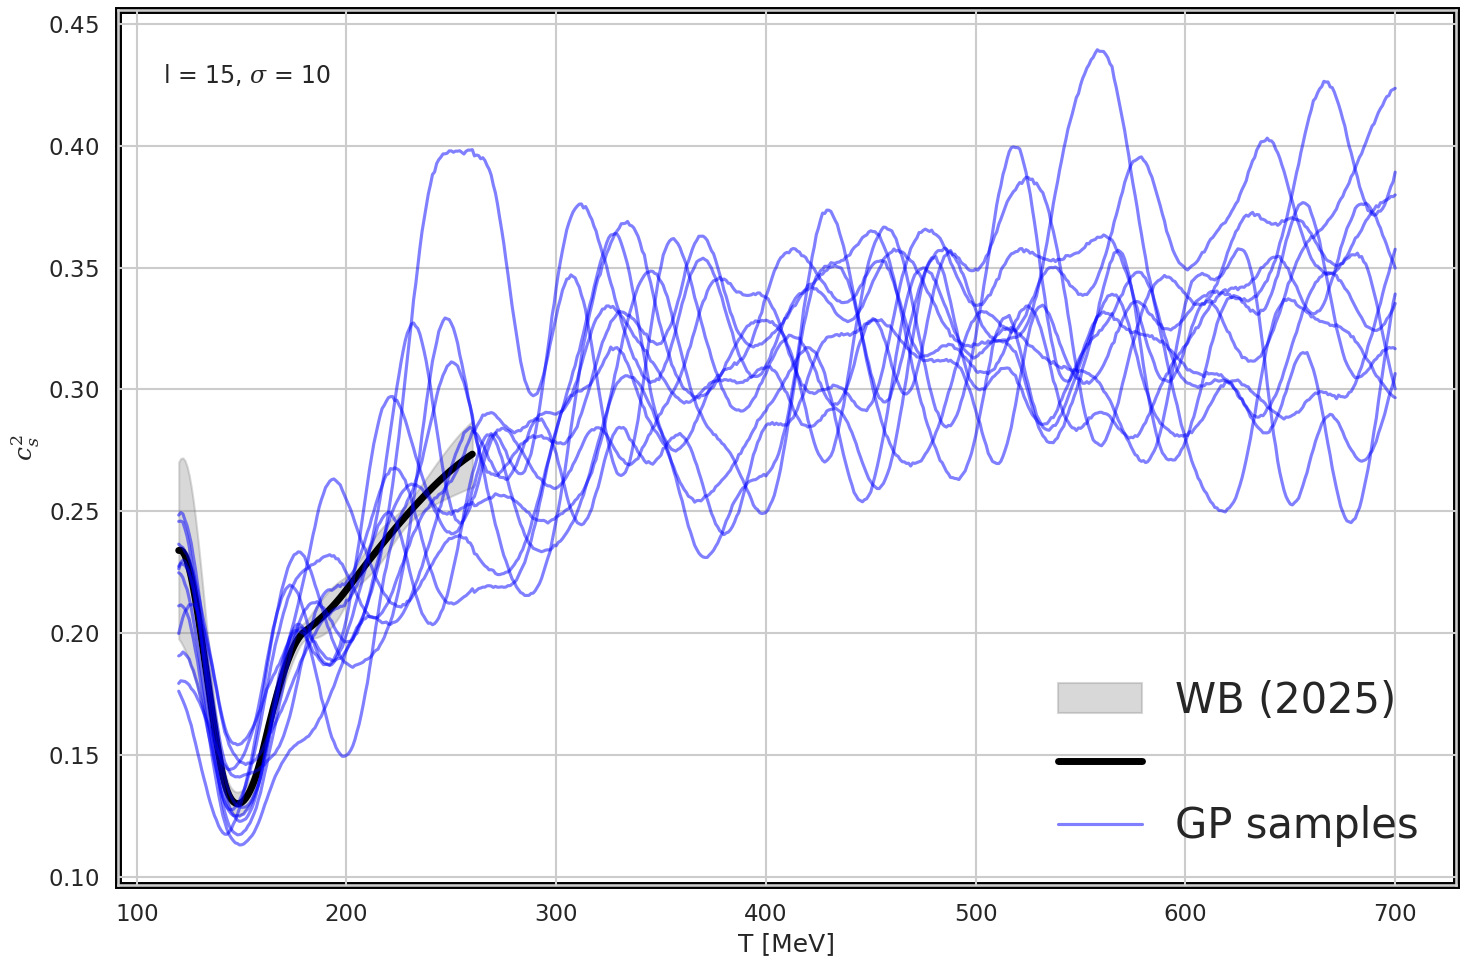

In [11]:
# Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

# Lattice error band
ax.fill_between(
    lattice_cs2['T'],
    lattice_cs2['cs2'] - lattice_cs2['error'],
    lattice_cs2['cs2'] + lattice_cs2['error'],
    alpha=0.3,
    color='gray',
    label='WB (2025)'
)

# Lattice mean line
sns.lineplot(
    data=lattice_cs2,
    x='T',
    y='cs2',
    ax=ax,
    color='black',
    linewidth=5,
    label=' '
)

for i in range(11):
    l_plot1 = 15
    sigma_plot1 = 10
    cs2_sample_plot1 = generate_sample(l_plot1, sigma_plot1)

    ax.plot(
        T_stepOne_total,
        cs2_sample_plot1,
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    # ax.plot(
    #     T_down,
    #     y_down,
    #     color='blue',
    #     alpha=0.5,
    #     #label='GP samples' if i == 0 else None
        
    #)

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)
plt.figtext(0.12, 0.9,  f'l = {l_plot1}, $\sigma$ = {sigma_plot1}', size=17)

plt.tight_layout()
plt.savefig('./images/cs2.png')
plt.show()



## HRG

In [12]:
file_path = "./pdg-urqmd_v3.3+.dat"

if not os.path.isfile(file_path):
    print("Unable to open file")
    exit(1)

m_bosons = []
m_fermions = []
g_b = []
g_f = []

with open(file_path, "r") as file:
    for line in file:
        
        #removes whitespace characters, including spaces, tabs, and newlines
        line = line.strip() 
        
        if not line:
            continue  # skip empty lines

        values = line.split()

        if values[1][0].isalpha():
            try:
                mass = float(values[2])
                f_or_b = int(values[5])
                g = float(values[4])
                mass_mev = mass * 1e3  #MeV

                if f_or_b == 1:
                    m_fermions.append(mass_mev)
                    g_f.append(g)
                elif f_or_b == 0:
                    m_bosons.append(mass_mev)
                    g_b.append(g)
            except ValueError:
                continue  
        elif values[1][0].isdigit():
            continue  


In [13]:
def bose_einstein(k, T, mass):
    x = np.sqrt(k**2 + mass**2)/T
    x = np.float128(x)
    return 1.0/(np.expm1(x))

def fermi_dirac(k, T, mass):
    x = np.sqrt(k**2 + mass**2)/T
    x = np.float128(x)
    return 1.0/(np.expm1(x) +1 + 1)

def pressure_integrand(k, g, T, mass, eta):
    if eta == 1:
        return (g/(6.0*(np.pi)**2))*(k**4)*fermi_dirac(k, T, mass)/(np.sqrt(k**2 + mass**2))
    elif eta == 0:
        return (g/(6.0*(np.pi)**2))*(k**4)*bose_einstein(k, T, mass)/(np.sqrt(k**2 + mass**2))
    else:
        raise ValueError("eta must be 0 or 1")

def energy_integrand(k, g, T, mass, eta):
    if eta == 1:
        return (g/(2*(np.pi)**2))*(k**2)*(np.sqrt(k**2 + mass**2))*fermi_dirac(k, T, mass)
    elif eta == 0:
        return (g/(2*(np.pi)**2))*(k**2)*(np.sqrt(k**2 + mass**2))*bose_einstein(k, T, mass)

In [14]:
T_sw = 150 #MeV

def pressure_hrg(T, m_fermions, g_f, m_bosons, g_b):
    total = 0.0
    for m, g in zip(m_fermions, g_f):
        result, _ = quad(pressure_integrand, 0, 10000, args=(g, T, m, 1), limit=200)
        total += result

    for m, g in zip(m_bosons, g_b):
        result, _ = quad(pressure_integrand, 0, 10000, args=(g, T, m, 0), limit=200)
        total += result

    return total  # MeV^4

def energy_hrg(T, m_fermions, g_f, m_bosons, g_b):
    total = 0.0
    for m, g in zip(m_fermions, g_f):
        result, _ = quad(energy_integrand, 0, 10000, args=(g, T, m, 1), limit=200)
        total += result

    for m, g in zip(m_bosons, g_b):
        result, _ = quad(energy_integrand, 0, 10000, args=(g, T, m, 0), limit=200)
        total += result

    return total  # MeV^4

P_sw = pressure_hrg(T_sw, m_fermions, g_f, m_bosons, g_b) #MeV^4
e_sw = energy_hrg(T_sw, m_fermions, g_f, m_bosons, g_b) #MeV^4
s_sw =  (P_sw + e_sw)/T_sw #MeV^3

In [15]:
print(P_sw*MeV4_to_GeV_fm3)
print(e_sw*MeV4_to_GeV_fm3)
print(s_sw*(1/hbarc**3))
print(s_sw)

0.05254009465837943
0.2533134803289631
2.03902383324895
15660425.500159467


## Thermodynamics from sample

In [48]:
cs2_sample_list = generate_sample(10, 15) #every time you tun this cell it changes all other results from below

cs2_interp = interp1d(T_stepOne_total, cs2_sample_list)

#ranges in temperature with smaller stepsize

T_pointZeroOne_up = np.linspace(120, 700, int((700 - 120) / 0.01) + 1)
T_pointOne_down = np.round(np.arange(0, 119.9 + 0.001, 0.1), 10)
T_total = np.concatenate((T_pointOne_down, T_pointZeroOne_up))

T_pointOne_110 = T_pointOne_down[0:1100]
T_concatenate_110to120 = np.concatenate([T_pointOne_110, T_pointZeroOne_up])

#region in which we do the interpolation from HRG to values from sample
T_transitionRegion = T_total[1100:1200]

T_test= np.round(np.arange(80, 140 + 0.001, 0.1), 10)

In [19]:
print(len(T_pointZeroOne_up))
print(len(T_total))
print(T_total[500])
print(T_pointOne_down[0] - T_pointOne_down[1])
print(T_pointZeroOne_up[0] - T_pointZeroOne_up[1])

58001
59201
50.0
-0.1
-0.010000000000005116


In [20]:
def s_integrand(T, cs2_interp): 
    return 1 / (T * cs2_interp(T))

def entropy_up(s_sw, T_sw, cs2_interp, T_up):

    integrand = s_integrand(T_up, cs2_interp)
    integral = cumulative_trapezoid(integrand, T_up, initial=0)

    Int_at_Tsw = np.interp(T_sw, T_up, integral)
    integral -= Int_at_Tsw

    s_up_vec = s_sw * np.exp(integral)
    s_interp = interp1d(T_up, s_up_vec)

    return s_interp

s_up_interp = entropy_up(s_sw, T_sw, cs2_interp, T_pointZeroOne_up)

In [107]:
#old integration method for comparison

def entropy_up_old(s_sw, T_sw, cs2_interp, T_up):
    s_up = []
        
    for T in T_up:
        if T < T_sw:
            integral, _ = quad(s_integrand, T, T_sw, args=(cs2_interp,), epsabs=1e-3, epsrel=1e-3, limit=1000)
            s = s_sw * np.exp(-integral)
        elif T > T_sw:
            integral, _ = quad(s_integrand, T_sw, T, args=(cs2_interp,), epsabs=1e-3, epsrel=1e-3, limit=1000)
            s = s_sw * np.exp(integral)
        else:
            s = s_sw
        s_up.append(s)
    return s_up

s_up_old = entropy_up_old(s_sw, T_sw, cs2_interp, T_pointZeroOne_up)

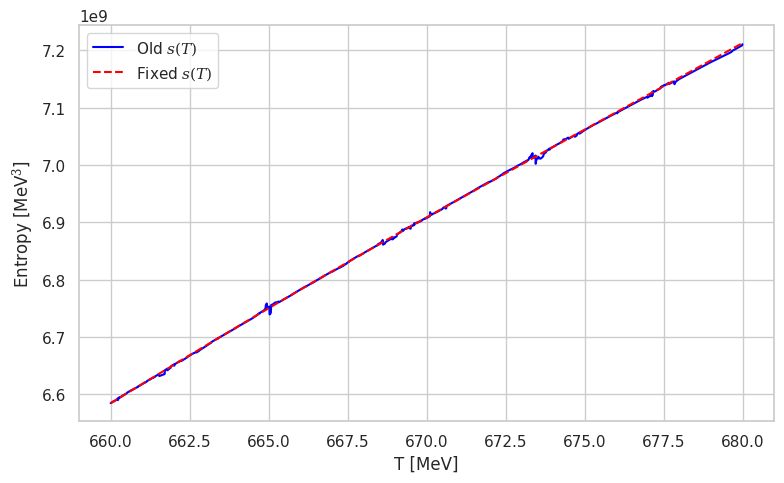

In [108]:
plt.figure(figsize=(8, 5))

plt.plot(T_pointZeroOne_up[54000:56000], s_up_old[54000:56000],
         '-', linewidth=1.5, color='blue', label='Old $s(T)$')

plt.plot(T_pointZeroOne_up[54000:56000],s_up_interp(T_pointZeroOne_up[54000:56000]),
         '--', linewidth=1.5, color='red', label='Fixed $s(T)$')

plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/integral_comparison.png')
plt.show()


/tmp/ipykernel_237231/2906098947.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


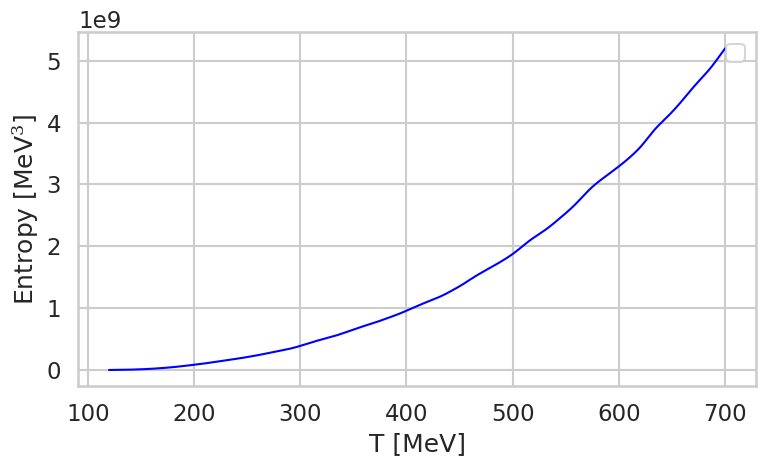

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(T_pointZeroOne_up, s_up_interp(T_pointZeroOne_up),
         '-', linewidth=1.5, color='blue', label = None)

plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.grid(True)
plt.tight_layout()
#plt.savefig('./images/integral_comparison.png')
plt.show() 

In [22]:
#pressure old integration method for comparison

def P_integrand(T, s_interp):
    return s_interp(T)

def pressure_up(P_sw, T_sw, T_vec, s_interp):
    pressure = []
    for T in T_vec:
        if T < T_sw:
            integral, _ = quad(P_integrand, T, T_sw, args=(s_interp,), epsabs=1e-3, epsrel=1e-3, limit=600)
            p = P_sw - integral
        elif T > T_sw:
            integral, _ = quad(P_integrand, T_sw, T, args=(s_interp,), epsabs=1e-3, epsrel=1e-3, limit=600)
            p = P_sw + integral
        else:
            p = P_sw
        pressure.append(p)
    return pressure

P_up_vec = pressure_up(P_sw, T_sw, T_pointZeroOne_up, s_up_interp)
P_up_interp = interp1d(T_pointZeroOne_up, P_up_vec)

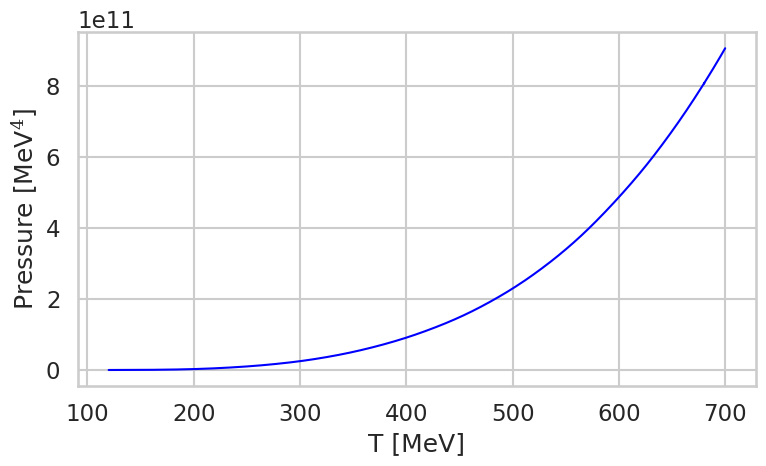

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(T_pointZeroOne_up, P_up_vec,
         '-', linewidth=1.5, color='blue', label=None)

plt.xlabel('T [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.grid(True)
plt.tight_layout()
#plt.savefig('./images/integral_comparison.png')
plt.show()

In [24]:
#energy upwards

def energy_up(s, P, T_vec):
    energy_vec = []
    for T in T_vec:
        energy_vec.append(s(T)*T - P(T))
    return energy_vec

e_up_vec = energy_up(s_up_interp, P_up_interp, T_pointZeroOne_up)

/tmp/ipykernel_237231/2510636107.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


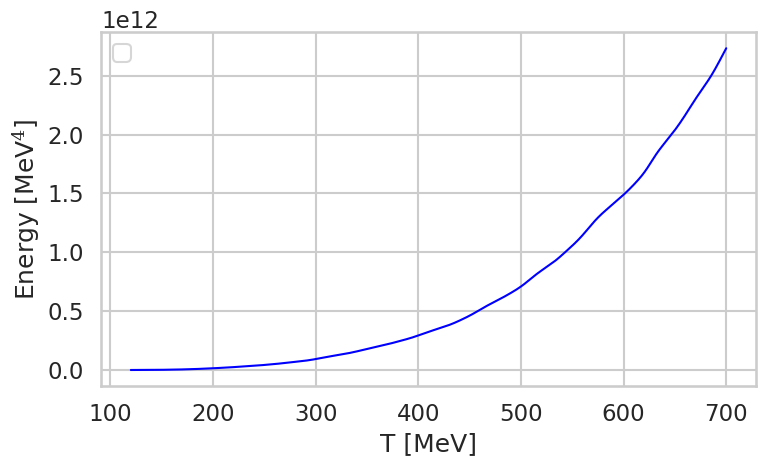

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(T_pointZeroOne_up, e_up_vec,
         '-', linewidth=1.5, color='blue', label=None)

plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.grid(True)
plt.tight_layout()
#plt.savefig('./images/integral_comparison.png')
plt.show()

## Downwards extrap

### Using a power law

In [26]:
#s_down

def s_extrap_pwr(T, T_up, s_up_interp, P_up_interp):
    T0 = T_up[0]
    s0 = s_up_interp(120)
    p0 = P_up_interp(120)

    n = (T0*s0/p0) - 1
    a_s = s0 / T0**n
    return a_s * T**n

#vector of entropy for the whole range
s_total_pwr =  np.concatenate([s_extrap_pwr(T_pointOne_down, T_pointZeroOne_up, s_up_interp, P_up_interp), s_up_interp(T_pointZeroOne_up)])

s_interp_pwr = interp1d(T_total, s_total_pwr, kind='cubic')

sT_vec_pwr = []
for T in T_total:
    sT_vec_pwr.append(s_interp_pwr(T)*T)

In [27]:
#pressure downwards

def P_extrap_pwr(T, T_up, s_up_interp, P_up_interp):
    T0 = T_up[0]
    s0 = s_up_interp(120)
    p0 = P_up_interp(120)

    n = (T0*s0/p0) - 1
    a_s = s0 / T0**n
    return (a_s*T**(n+1))/(n+1) 

#vector of pressure for the whole range
P_total_pwr = np.concatenate([P_extrap_pwr(T_pointOne_down, T_pointZeroOne_up, s_up_interp, P_up_interp), P_up_vec])

P_interp_pwr = interp1d(T_total, P_total_pwr)


In [28]:
#energy downwards

e_extrap_pwr = []
for i, T in enumerate(T_pointOne_down):
    s = s_extrap_pwr(T, T_pointZeroOne_up, s_up_interp, P_up_interp)             
    p = P_extrap_pwr(T, T_pointZeroOne_up, s_up_interp, P_up_interp)             
    e = s * T - p             
    e_extrap_pwr.append(e)

#vector of energy for the whole range
e_total_pwr = np.concatenate([e_extrap_pwr, e_up_vec])

e_interp_pwr = interp1d(T_total, e_total_pwr)

In [29]:
with open("./check_files/thermo_check_powerlaw.txt", "w") as f:
    for i, T in enumerate(T_total):
        s_value = s_interp_pwr(T)
        p_value = P_interp_pwr(T)
        e_value = e_interp_pwr(T)
        check = e_value + p_value
        expected = s_value * T
        diff = abs(check - expected)

        f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")

        if diff > 1e-3:
            print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}")


Discrepancy at T = 664.58 MeV: e + p = 2963032265171.201172, s*T = 2963032265171.202637, diff = 1.46e-03
Discrepancy at T = 665.65 MeV: e + p = 2982557359148.039062, s*T = 2982557359148.037598, diff = 1.46e-03
Discrepancy at T = 668.33 MeV: e + p = 3031234125011.045898, s*T = 3031234125011.047363, diff = 1.46e-03
Discrepancy at T = 668.75 MeV: e + p = 3038800135024.038086, s*T = 3038800135024.036621, diff = 1.46e-03
Discrepancy at T = 669.27 MeV: e + p = 3048137995013.733398, s*T = 3048137995013.731934, diff = 1.46e-03
Discrepancy at T = 673.42 MeV: e + p = 3121303601769.453125, s*T = 3121303601769.454590, diff = 1.46e-03
Discrepancy at T = 677.75 MeV: e + p = 3195969793880.657227, s*T = 3195969793880.655762, diff = 1.46e-03
Discrepancy at T = 679.27 MeV: e + p = 3222296693663.528320, s*T = 3222296693663.526855, diff = 1.46e-03
Discrepancy at T = 683.95 MeV: e + p = 3306070216029.791016, s*T = 3306070216029.792480, diff = 1.46e-03
Discrepancy at T = 689.14 MeV: e + p = 3407400400743.25

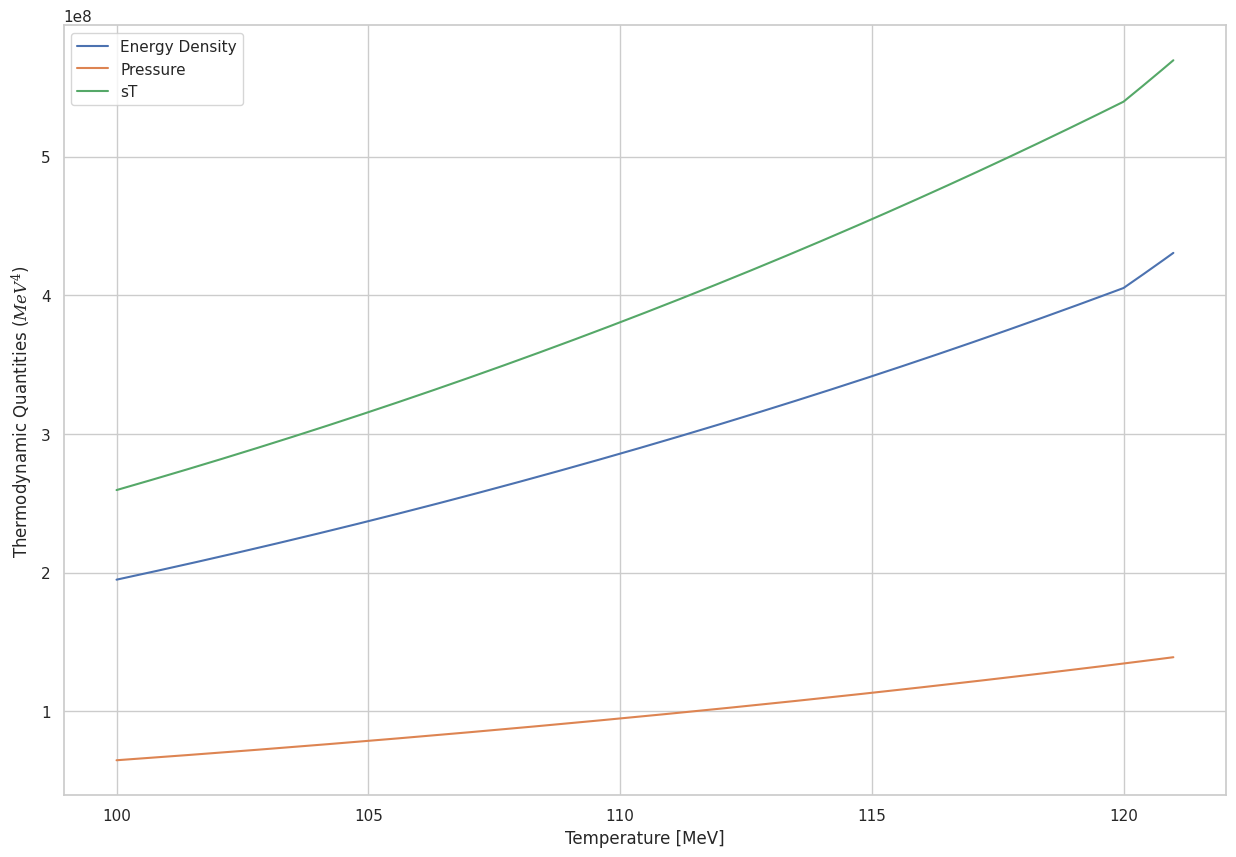

In [30]:
#all thermo plots

df = pd.DataFrame({'T': T_total[1000:1300], 'Entropy': s_total_pwr[1000:1300], 'Energy': e_total_pwr[1000:1300], 
                   'Pressure': P_total_pwr[1000:1300], 'sT': sT_vec_pwr[1000:1300]})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='Energy', label='Energy Density')
sns.lineplot(data=df, x='T', y='Pressure', label='Pressure')
sns.lineplot(data=df, x='T', y='sT', label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('Thermodynamic Quantities ($ MeV^4$)')
plt.legend()
plt.savefig('./images/power_extrap.png')
plt.show()

In [31]:
#cs2_vector

def cs2_extrap_pwr(T_down, T_up, s_up_interp, P_up_interp):
    cs2_down = []
    T0 = T_up[0]
    s0 = s_up_interp(120)
    p0 = P_up_interp(120)

    n = (T0*s0/p0) - 1

    for T in T_down:
        cs2_down.append(1/n)

    return cs2_down
    
#vector of cs2 for the whole range
#since cs2 isnt automatically continuous, we only extrapolate up to T = 110 MeV and do a linear interp in the transition region to 120 MeV    
cs2_total_pwr = np.concatenate([cs2_extrap_pwr(T_pointOne_down[0:1100], T_pointZeroOne_up, s_up_interp, P_up_interp), cs2_interp(T_pointZeroOne_up)])

cs2_interp_pwr = interp1d(T_concatenate_110to120, cs2_total_pwr, kind='quadratic')

In [41]:
# sns.set(style="whitegrid", context="talk")

# fig1, axs1 = plt.subplots(4, 1, figsize=(10, 15), sharex=True)
# fig2, axs2 = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

# cmap = cm.get_cmap('tab10', 7)  
# colors = [cmap(i) for i in range(7)]

# for i in range(4):
#     s_plot = []
#     p_plot = []
#     e_plot = []
#     T_divide = T_total[500:]
    
#     cs2_sample_plot = generate_sample(10, 15)
#     cs2_interp_plot = interp1d(T_sampling, cs2_sample_plot)

#     s_up_interp_plot = entropy_up(s_sw, T_sw, cs2_interp_plot, T_range_up)

#     P_up_vec = pressure_up(P_sw, T_sw, T_range_up, s_up_interp_plot)
#     P_up_interp_plot = interp1d(T_range_up, P_up_vec)

#     s_plot = np.concatenate([s_extrap_pwr(T_range_down, T_range_up, s_up_interp_plot, P_up_interp_plot), 
#                                   s_up_interp_plot(T_range_up)])

#     P_plot = np.concatenate([P_extrap_pwr(T_range_down, T_range_up, s_up_interp_plot, P_up_interp_plot), 
#                                P_up_interp_plot(T_range_up)])

#     e_plot = s_plot*T_total - P_plot

#     cs2_vec_plot = np.concatenate([cs2_extrap_pwr(T_range_down[0:1100], T_range_up, s_up_interp_plot, P_up_interp_plot), cs2_interp_plot(T_range_up)])

#     cs2_pwr_plot = interp1d(T_interp_cs2, cs2_vec_plot, kind='quadratic')

#     color = colors[i] 
#     axs1[0].plot(T_total, s_plot*(1/hbarc**3), color=color, alpha=0.5, label='entropy' if i == 0 else None)
#     axs1[1].plot(T_total, P_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='pressure' if i == 0 else None)
#     axs1[2].plot(T_total, e_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='energy' if i == 0 else None)
#     axs1[3].plot(T_total, cs2_pwr_plot(T_total), color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

#     axs2[0].plot(T_divide, s_plot[500:] / T_divide**3, color=color, alpha=0.5, label='entropy' if i == 0 else None)
#     axs2[1].plot(T_divide, P_plot[500:] / T_divide**4, color=color, alpha=0.5, label='pressure' if i == 0 else None)
#     axs2[2].plot(T_divide, e_plot[500:] / T_divide**4, color=color, alpha=0.5, label='energy' if i == 0 else None)
#     axs2[3].plot(T_divide, cs2_pwr_plot(T_total[500:]), color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

# # Labels and layout
# axs1[0].set_ylabel(r"$s(T) (1/fm^3)$")
# axs1[1].set_ylabel(r"$p(T) (GeV/fm^3)$")
# axs1[2].set_ylabel(r"$e(T) (GeV/fm^3)$")
# axs1[3].set_ylabel(r"$c_s^2(T)$")
# axs1[3].set_xlabel("Temperature T")

# axs2[0].set_ylabel(r"$s(T)/T^3 (1/fm^3)$")
# axs2[1].set_ylabel(r"$p(T)/T^4 (GeV/fm^3)$")
# axs2[2].set_ylabel(r"$e(T)/T^4 (GeV/fm^3)$")
# axs2[3].set_ylabel(r"$c_s^2(T)$")
# axs2[3].set_xlabel("Temperature T")

# for ax in axs1:
#     ax.legend()
#     ax.grid(True)

# for ax in axs2:
#     ax.legend()
#     ax.grid(True)

# plt.tight_layout()
# plt.savefig('./images/eos_pwr_change_hyper.png')
# plt.show()


### Using HRG and performing a weighted interpolation in a transition region

In [32]:
def P_extrap_hrg(T, m_fermions, g_f, m_bosons, g_b):
    p_down = []
    for temp in T: 
        total = 0.0
        for m, g in zip(m_fermions, g_f):
            if temp <= 1:
                total += 0.0
            else:
                result, _ = quad(pressure_integrand, 0, 10000, args=(g, temp, m, 1), limit=200)
                total += result

        for m, g in zip(m_bosons, g_b):
            if temp <=1:
                total += 0.0
            else:
                result, _ = quad(pressure_integrand, 0, 10000, args=(g, temp, m, 0), limit=200)
                total += result

        #print(temp, total)
        p_down.append(total)

    return p_down  # MeV^4

def e_extrap_hrg(T, m_fermions, g_f, m_bosons, g_b):
    e_down = []
    for temp in T: 
        total = 0.0     
        for m, g in zip(m_fermions, g_f):
            if temp <= 1:
                total += 0.0
            else:
                result, _ = quad(energy_integrand, 0, 10000, args=(g, temp+0.08, m, 1), limit=200)
                total += result

        for m, g in zip(m_bosons, g_b):
            if temp <= 1:
                total += 0.0
            else:
                result, _ = quad(energy_integrand, 0, 10000, args=(g, temp+0.08, m, 0), limit=200)
                total += result

        e_down.append(total)

    return e_down  # MeV^4

In [33]:
#HRG vectors low T

P_hrg_vec_110 = P_extrap_hrg(T_pointOne_110, m_fermions, g_f, m_bosons, g_b)
e_hrg_vec_110 = e_extrap_hrg(T_pointOne_110, m_fermions, g_f, m_bosons, g_b)

s_hrg_vec_110 =[]
for i in range(0, len(e_hrg_vec_110)):
    if i == 0:
        s_hrg_vec_110.append(0)
    else:
        s_hrg_vec_110.append((e_hrg_vec_110[i] + P_hrg_vec_110[i])/T_pointOne_110[i])

In [46]:
# weighted monotonic function old
# def weighted_monotonic(vec_down, vec_up):
#     vec_down = np.asarray(vec_down, dtype=float)
#     vec_up = np.asarray(vec_up, dtype=float)
#     # Default to the last value of vec_down if condition is never met
#     initial_val = vec_down[-1]
#     w_range = np.linspace(0, 1, 100)
#     vec_T_len = len(np.concatenate([vec_down, w_range, vec_up]))
#     for el, i in zip(vec_down, range(len(vec_down))):
#         if el > vec_up[0]:
#             #print(i-10) 
#             initial_val = vec_down[i-20] if i >= 20 else vec_down[0]
#             w_range = np.linspace(0, 1, vec_T_len - len(vec_up) - len(vec_down[0:i-20]))
#             vec_down = vec_down[0:i-20]
#             break 
#     weighted_vec = [weighted_interp(x, initial_val, vec_up[0]) for x in w_range]
#     #print(len(weighted_vec))
#     vec_total = np.concatenate([vec_down, weighted_vec, vec_up])
#     return vec_total 

In [34]:
#interpolation w/ weights

w_range = np.linspace(0, 1, 100)

def weighted_interp(x, val_down, val_up):
    return (1 - x) * val_down + x * val_up


def weightedExtrap(vec_down, vec_up, n_transition=100):
    vec_down = np.asarray(vec_down, dtype=float)
    vec_up   = np.asarray(vec_up, dtype=float)

    up_start = vec_up[0]

    # --- Find last index in vec_down that is STRICTLY below vec_up[0]
    valid_indices = np.where(vec_down < up_start)[0]

    if len(valid_indices) == 0:
        # Edge case: everything in vec_down is above vec_up[0], no valid index
        cut_idx = 0
    elif vec_down[-1] > up_start:
        cut_idx = valid_indices[-15]
        print(cut_idx)
    else:
        cut_idx = valid_indices[-1] + 1 # keep until this index
        print('last valid index is ' + str(valid_indices[-1]))

    vec_down_cut = vec_down[:cut_idx]

    # --- Define original total size (same as before cutting)
    N_total = len(vec_down) + n_transition + len(vec_up)

    # --- Define transition endpoints
    start_val = vec_down_cut[-1] if len(vec_down_cut) > 0 else up_start
    end_val   = up_start

    # --- Adjust transition size to preserve total length   
    n_transition = N_total - len(vec_down_cut) - len(vec_up)
    print('n_transition adjusted to ' + str(n_transition))

    # --- Build weights from 0 to 1
    diff = N_total - (len(vec_down_cut) + n_transition + len(vec_up))
    w_range = np.linspace(0, 1, n_transition, endpoint=False)
    
    print('len vec_down = ' + str(len(vec_down_cut)) + ' len weights = ' + str(len(w_range)) + 
        ' len vec_up = ' + str(len(vec_up)) + ' such that the difference should be zero = ' + str(diff))

    # --- Apply weights to interpolate values
    transition = np.array([
        weighted_interp(w, start_val, end_val) for w in w_range
    ])


    # --- Final concatenation
    vec_total = np.concatenate([
        vec_down_cut,
        transition,
        vec_up
    ])

    print('Final length check: ' + str(len(vec_total)) + ' should be ' + str(N_total))

    return vec_total


last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


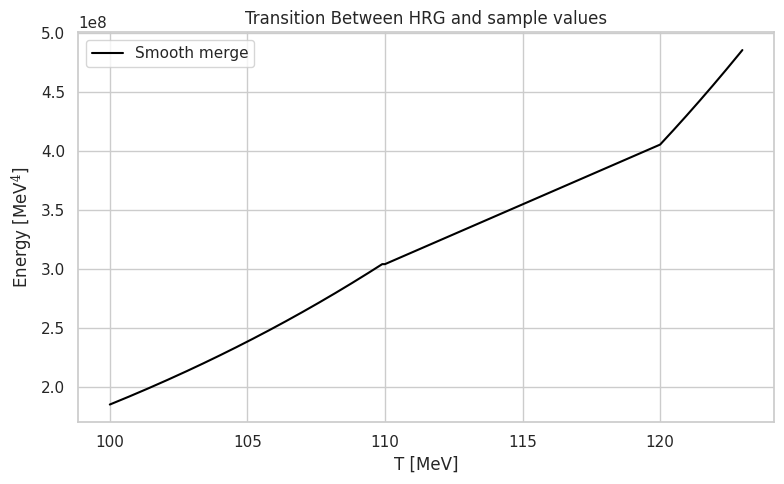

In [35]:
# Energy transition plot

e_merged = weightedExtrap(e_hrg_vec_110, e_up_vec)

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1500], e_merged[1000:1500] , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/hrg_e_transition.png')
plt.show()

last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


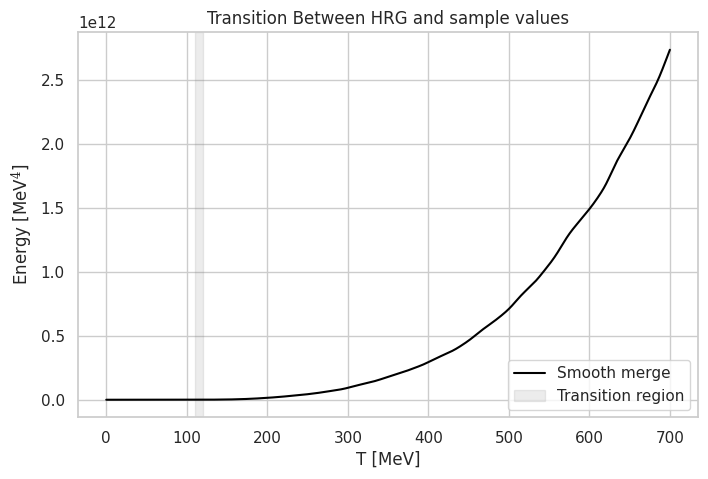

In [36]:
#energy full range

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total, weightedExtrap(e_hrg_vec_110, e_up_vec) , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
#plt.savefig('./images/hrg_e_transition.png')
plt.show()

last valid index is 99
n_transition adjusted to 100
len vec_down = 100 len weights = 100 len vec_up = 200 such that the difference should be zero = 0
Final length check: 400 should be 400


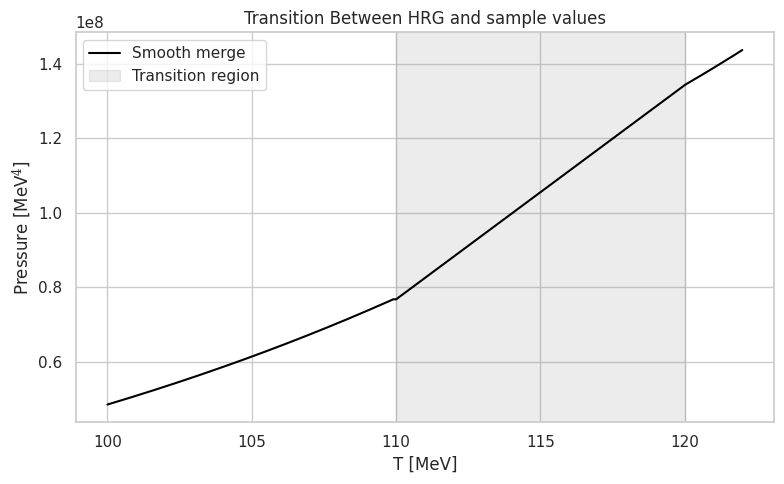

In [37]:
# P transition plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1400], weightedExtrap(P_hrg_vec_110[1000:1400], P_up_vec[0:200]) , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/hrg_P_transition.png')
plt.show()

last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


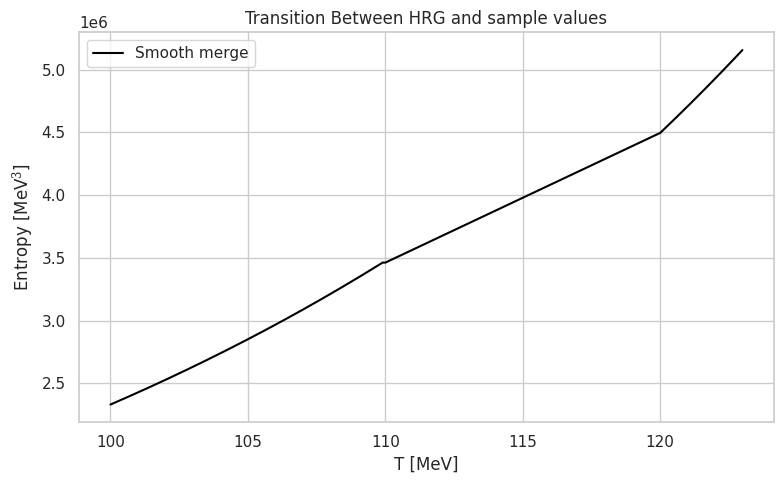

In [38]:
#s transition plot

#s_plot = (weightedExtrap(e_hrg_vec_110, e_up_vec) +  weightedExtrap(P_hrg_vec_110, P_up_vec))/T_total
s_plot = weightedExtrap(s_hrg_vec_110, s_up_interp(T_pointZeroOne_up))

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1500], s_plot[1000:1500], '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/hrg_s_transition.png')
plt.show()

In [39]:
#checking thermodynamic consistency

with open("./check_files/thermo_check_hrg.txt", "w") as f:
    p = weightedExtrap(P_hrg_vec_110, P_up_vec)
    e = weightedExtrap(e_hrg_vec_110, e_up_vec)
    s = np.where(T_total != 0, (p + e) / T_total, 0.0)

    for i, T in enumerate(T_total):
        s_value = s[i]
        p_value = p[i]
        e_value = e[i]
        check = e_value + p_value
        expected = s_value * T
        diff = abs(check - expected)

        f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")

        if diff > 1e-3:
            print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}")

last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201
last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


/tmp/ipykernel_237231/3826835966.py:6: RuntimeWarning: invalid value encountered in divide
  s = np.where(T_total != 0, (p + e) / T_total, 0.0)


In [45]:
#cs2 from HRG to upper region (beggining in 120 MeV) interpolating

dP_dT = np.gradient(P_hrg_vec_110, T_pointOne_110)
de_dT = np.gradient(e_hrg_vec_110, T_pointOne_110)

with np.errstate(invalid='ignore', divide='ignore'):
    cs2_hrg_to_interp = dP_dT / de_dT

# Fill NaNs with first valid non-NaN value
cs2_hrg_to_interp[np.isnan(cs2_hrg_to_interp)] = cs2_hrg_to_interp[~np.isnan(cs2_hrg_to_interp)][0]

#vector of cs2 for the whole range
cs2_total_w = np.concatenate([cs2_hrg_to_interp, cs2_interp(T_pointZeroOne_up)])

cs2_interp_w = interp1d(T_concatenate_110to120, cs2_total_w, kind='quadratic')

In [49]:
#cs2 from HRG discontinuous at 120 MeV

P_hrg_to_120 = P_extrap_hrg(T_pointOne_down, m_fermions, g_f, m_bosons, g_b)
e_hrg_to_120 = e_extrap_hrg(T_pointOne_down, m_fermions, g_f, m_bosons, g_b)

dP_dT_120disc = np.gradient(P_hrg_to_120, T_pointOne_down)
de_dT_120disc = np.gradient(e_hrg_to_120, T_pointOne_down)

with np.errstate(invalid='ignore', divide='ignore'):
    cs2_hrg_120disc = dP_dT_120disc / de_dT_120disc

# Fill NaNs with first valid non-NaN value
cs2_hrg_120disc[np.isnan(cs2_hrg_120disc)] = cs2_hrg_120disc[~np.isnan(cs2_hrg_120disc)][0]

In [50]:
cs2_120disc_total = np.concatenate([cs2_hrg_120disc, cs2_interp(T_pointZeroOne_up)])
cs2_120disc_interp = interp1d(T_total, cs2_120disc_total, kind='quadratic')

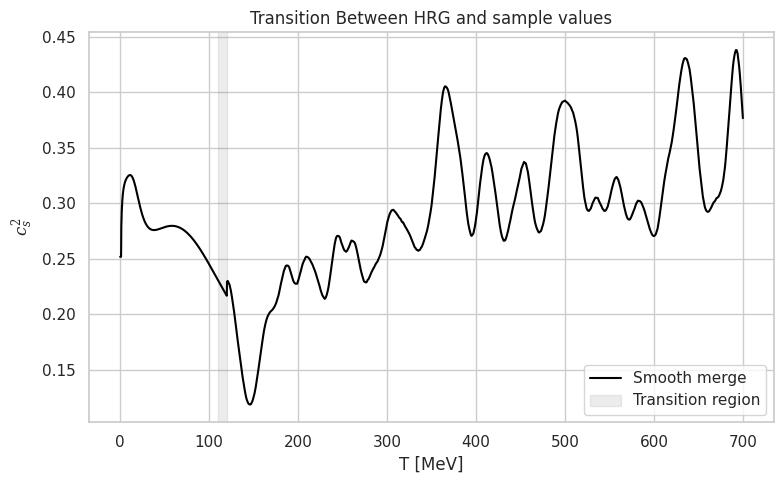

In [67]:
#cs2 interp plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total, cs2_120disc_interp(T_total) , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel(f'$c_s^2$')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/cs2_transition_disc120.png')
plt.show()

In [57]:
# sns.set(style="whitegrid", context="talk")

# fig1, axs1 = plt.subplots(4, 1, figsize=(10, 15), sharex=True)
# fig2, axs2 = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

# cmap = cm.get_cmap('tab10', 7)  
# colors = [cmap(i) for i in range(7)]

# cs2_all = [] 

# for i in range(4):
#     s_plot = []
#     p_plot = []
#     e_plot = []
#     T_divide = T_total[500:]
    
#     cs2_sample_plot = generate_sample(10, 15)
#     cs2_interp_plot = interp1d(T_sampling, cs2_sample_plot)

#     s_up_interp_plot = entropy_up(s_sw, T_sw, cs2_interp_plot, T_range_up)

#     P_up_vec = pressure_up(P_sw, T_sw, T_range_up, s_up_interp_plot)
#     P_up_interp_plot = interp1d(T_range_up, P_up_vec)

#     e_up_vec = s_up_interp_plot(T_range_up)*T_range_up - P_up_interp_plot(T_range_up)

#     p_plot = weighted_monotonic(P_hrg_vec_110, P_up_vec)

#     e_plot = weighted_monotonic(e_hrg_vec_110, e_up_vec)

#     s_plot = (p_plot + e_plot)/T_total

#     cs2_w_plot = np.concatenate([cs2_hrg_to_interp, cs2_interp_plot(T_range_up)])

#     cs2_interp_w_plot = interp1d(T_range_interp, cs2_w_plot, kind='quadratic')

#     color = colors[i] 
#     axs1[0].plot(T_total, s_plot*(1/hbarc**3), color=color, alpha=0.5, label='entropy' if i == 0 else None)
#     axs1[1].plot(T_total, p_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='pressure' if i == 0 else None)
#     axs1[2].plot(T_total, e_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='energy' if i == 0 else None)
#     axs1[3].plot(T_total, cs2_interp_w_plot(T_total), color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

#     axs2[0].plot(T_divide, s_plot[500:] / T_divide**3, color=color, alpha=0.5, label='entropy' if i == 0 else None)
#     axs2[1].plot(T_divide, p_plot[500:] / T_divide**4, color=color, alpha=0.5, label='pressure' if i == 0 else None)
#     axs2[2].plot(T_divide, e_plot[500:] / T_divide**4, color=color, alpha=0.5, label='energy' if i == 0 else None)
#     axs2[3].plot(T_divide, cs2_interp_w_plot(T_total[500:]), color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

# # Labels and layout
# axs1[0].set_ylabel(r"$s(T) (1/fm^3)$")
# axs1[1].set_ylabel(r"$p(T) (GeV/fm^3)$")
# axs1[2].set_ylabel(r"$e(T) (GeV/fm^3)$")
# axs1[3].set_ylabel(r"$c_s^2(T)$")
# axs1[3].set_xlabel("Temperature T")

# axs2[0].set_ylabel(r"$s(T)/T^3 (1/fm^3)$")
# axs2[1].set_ylabel(r"$p(T)/T^4 (GeV/fm^3)$")
# axs2[2].set_ylabel(r"$e(T)/T^4 (GeV/fm^3)$")
# axs2[3].set_ylabel(r"$c_s^2(T)$")
# axs2[3].set_xlabel("Temperature T")

# for ax in axs1:
#     ax.legend()
#     ax.grid(True)

# for ax in axs2:
#     ax.legend()
#     ax.grid(True)

# plt.tight_layout()
# plt.savefig('./images/eos_weighted.png')
# plt.show()

In [49]:
e_merged = weightedExtrap(e_hrg_vec_110, e_up_vec)
p_merged = weightedExtrap(P_hrg_vec_110, P_up_vec)
s_merged = np.where(T_total != 0, (p_merged + e_merged) / T_total, 0.0)

with open(f"./data_files/constrained/l10_s15/eos_w_sTest_l10_s15.dat", "w") as f:
        f.write(f"{len(e_merged)}\n")
        for e, T, p, cs2, s in zip(e_merged, T_total, p_merged, cs2_interp_w(T_total), s_merged):
            f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")


1046
n_transition adjusted to 154
len vec_down = 1046 len weights = 154 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201
last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


/tmp/ipykernel_229747/2623435833.py:3: RuntimeWarning: invalid value encountered in divide
  s_merged = np.where(T_total != 0, (p_merged + e_merged) / T_total, 0.0)


### Taking it as a HRG up to switching temperature

In [53]:
#HRG range
T_pointOne_150 = np.round(np.arange(0, 150+00.1, 0.1), 10)

P_hrg_vec_150 = P_extrap_hrg(T_pointOne_150, m_fermions, g_f, m_bosons, g_b)
e_hrg_vec_150 = e_extrap_hrg(T_pointOne_150, m_fermions, g_f, m_bosons, g_b)

s_hrg_vec_150 =[]
for i in range(0, len(e_hrg_vec_150)):
    if i == 0:
        s_hrg_vec_150.append(0)
    else:
        s_hrg_vec_150.append((e_hrg_vec_150[i] + P_hrg_vec_150[i])/T_pointOne_150[i])

In [54]:
P_total_150 = np.concatenate([P_hrg_vec_150, P_up_vec[3001:58001]])
e_total_150 = np.concatenate([e_hrg_vec_150, e_up_vec[3001:58001]])
s_total_150 = np.concatenate([s_hrg_vec_150, s_up_interp(T_pointZeroOne_up[3001:58001])])

In [55]:
P_hrg_interp = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:58001]]), P_total_150, kind='linear')
e_hrg_interp = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:58001]]), e_total_150, kind='linear')
s_hrg_interp = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:58001]]), s_total_150, kind='linear')

/tmp/ipykernel_237231/1256380368.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


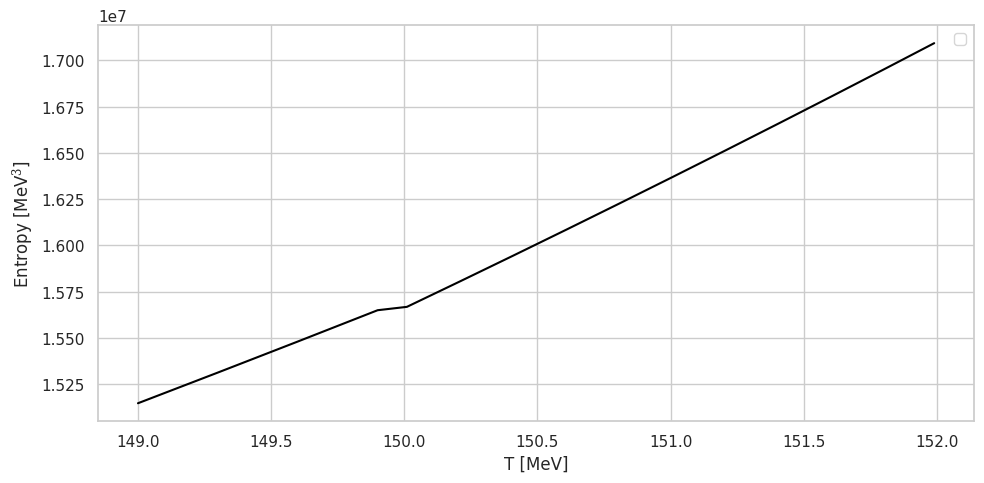

In [56]:
#s plot
plt.figure(figsize=(10, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

T_test_plot = np.concatenate([T_pointOne_150[1490:1500], T_pointZeroOne_up[3001:3200]])

plt.plot(T_test_plot, s_hrg_interp(T_test_plot) , '-', linewidth=1.5, color='black')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
#plt.title('Transition Between HRG and sample values')
plt.grid(True)

plt.tight_layout()
plt.savefig('./images/s_hrg_150_transition.png')
plt.show()


/tmp/ipykernel_237231/3268394927.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


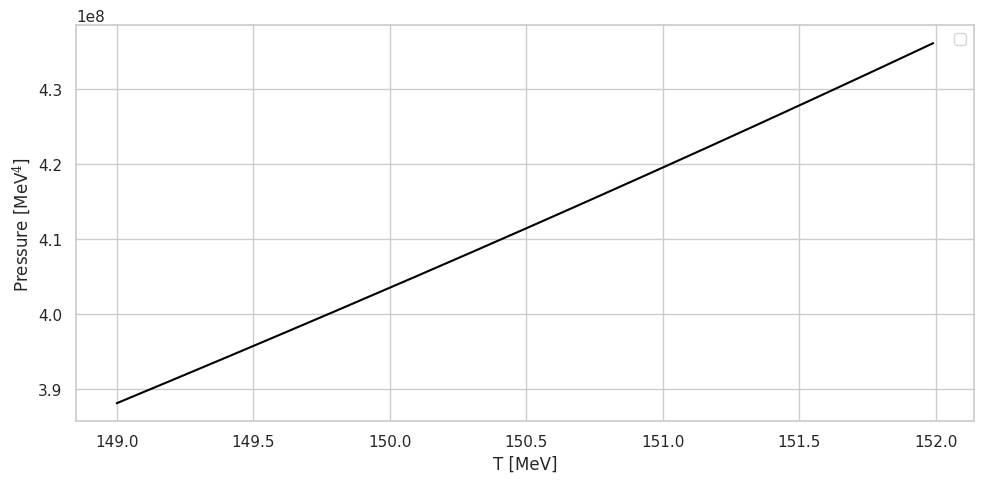

In [58]:
#P plot
plt.figure(figsize=(10, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_test_plot, P_hrg_interp(T_test_plot) , '-', linewidth=1.5, color='black')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.legend()
#plt.title('Transition Between HRG and sample values')
plt.grid(True)

plt.tight_layout()
plt.savefig('./images/P_hrg_150_transition.png')
plt.show()

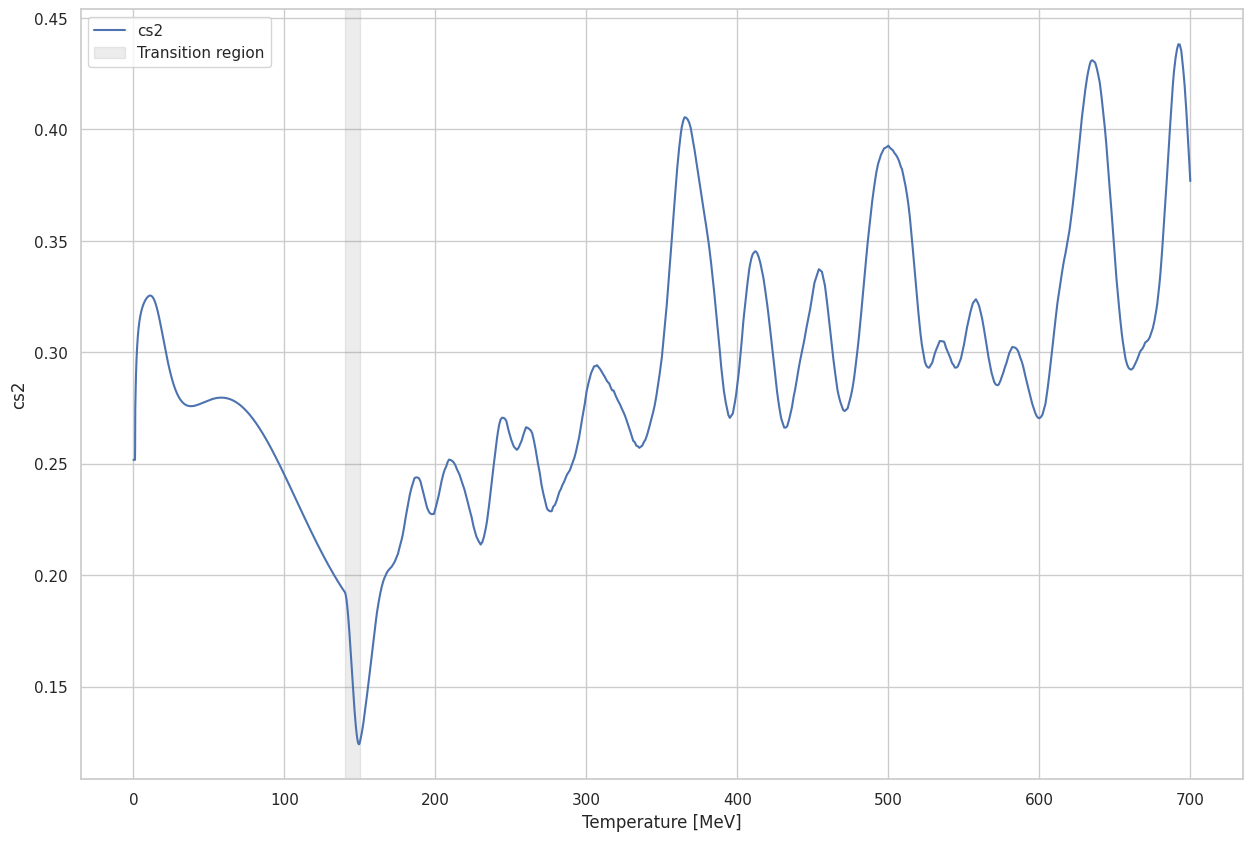

In [59]:
#cs2 plot

dP_dT = np.gradient(P_hrg_vec_150[:1400], T_pointOne_150[:1400])
de_dT = np.gradient(e_hrg_vec_150[:1400], T_pointOne_150[:1400])

with np.errstate(invalid='ignore', divide='ignore'):
    cs2_hrg_to_150 = dP_dT / de_dT

# Fill NaNs with first valid value
cs2_hrg_to_150[np.isnan(cs2_hrg_to_150)] = cs2_hrg_to_150[~np.isnan(cs2_hrg_to_150)][0]

cs2_to_150 = np.concatenate([cs2_hrg_to_150, cs2_interp(T_pointZeroOne_up[3001:])])

cs2_interp_150 = interp1d(np.concatenate([ T_pointOne_150[:1400],T_pointZeroOne_up[3001:] ]), cs2_to_150, kind='cubic')

df = pd.DataFrame({'T': T_total, 'cs2':cs2_interp_150(T_total)})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='cs2', label='cs2')

plt.xlabel('Temperature [MeV]')
plt.ylabel('cs2')
plt.axvspan(140, 150, color='gray', alpha=0.15, label='Transition region')
plt.legend()
plt.savefig('./images/cs2_transition_to_150.png')
plt.show()

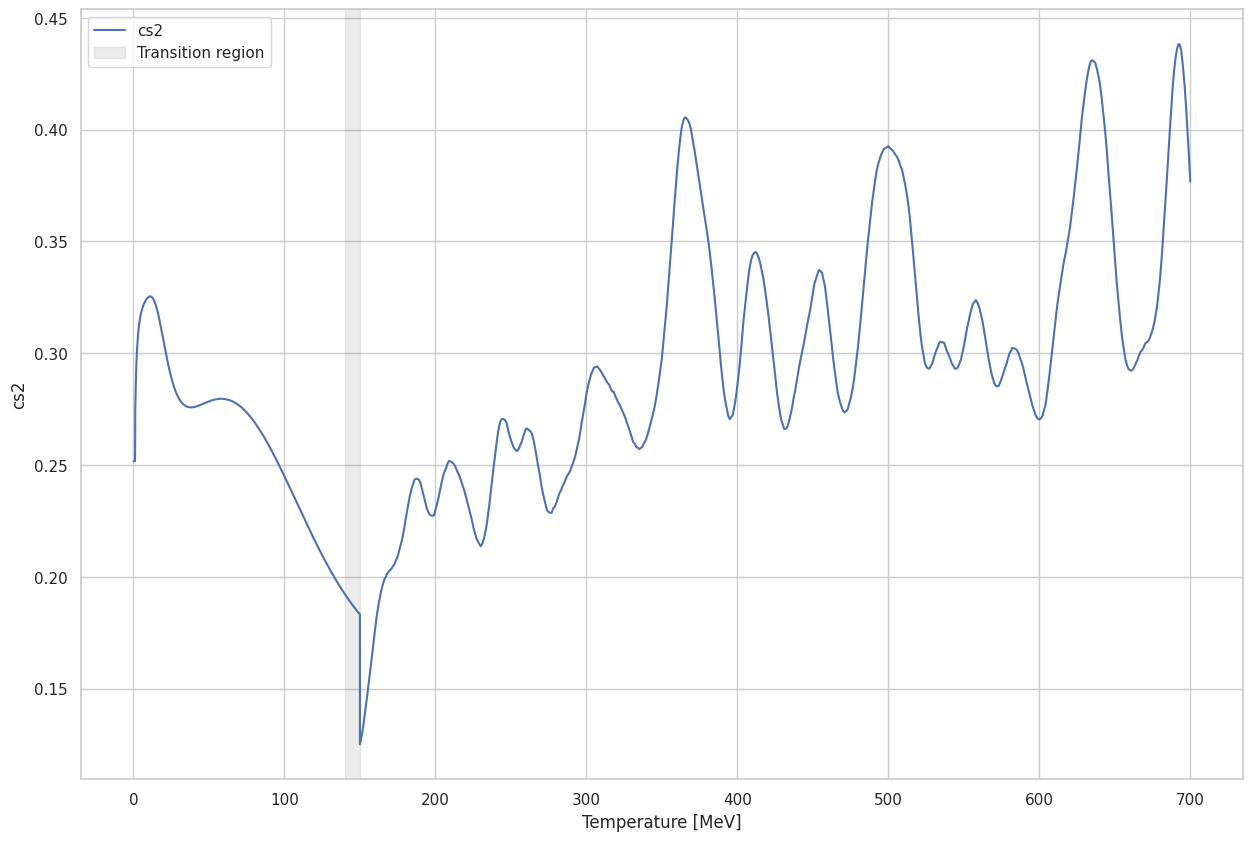

In [65]:
#without using interp1d, with the descontinuity

dP_dT_150disc = np.gradient(P_hrg_vec_150, T_pointOne_150)
de_dT_150disc = np.gradient(e_hrg_vec_150, T_pointOne_150)

with np.errstate(invalid='ignore', divide='ignore'):
    cs2_hrg_150disc = dP_dT_150disc / de_dT_150disc

# Fill NaNs with first valid value
cs2_hrg_150disc[np.isnan(cs2_hrg_150disc)] = cs2_hrg_150disc[~np.isnan(cs2_hrg_150disc)][0]

cs2_150disc_total = np.concatenate([cs2_hrg_150disc, cs2_interp(T_pointZeroOne_up[3001:])])
cs2_150disc_interp = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:]]), cs2_150disc_total, kind='linear')

df = pd.DataFrame({'T': T_total, 'cs2':cs2_150disc_interp(T_total)})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='cs2', label='cs2')

plt.xlabel('Temperature [MeV]')
plt.ylabel('cs2')
plt.axvspan(140, 150, color='gray', alpha=0.15, label='Transition region')
plt.legend()
plt.savefig('./images/cs2_transition_to_150_not_cont.png')
plt.show()

In [65]:
""" sns.set(style="whitegrid", context="talk")

fig, axs = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

cmap = cm.get_cmap('tab10', 7)  
colors = [cmap(i) for i in range(7)]

cs2_all = [] 

for i in range(4):
    entropy_total_plot = []
    pressure_total_plot = []
    energy_total_plot = []
    cs2_hrg_plot = []
    
    cs2_sample_plot = generate_sample()
    
    cs2_interp_plot = interp1d(T_sampling, cs2_sample_plot)

    s_up_vec = entropy_up(s_sw, T_sw, cs2_interp_plot, T_range_up)
    
    s_up_interp = interp1d(T_range_up, s_up_vec, kind='cubic', fill_value="extrapolate")

    P_up_vec = pressure_up(P_sw, T_sw, T_range_up, s_up_interp)

    e_up_vec = s_up_vec*T_range_up - P_up_vec

    pressure_total_plot = np.concatenate([pressure_hrg_vec, P_up_vec[301:5801]])
    energy_total_plot = np.concatenate([energy_hrg_vec, e_up_vec[301:5801]])
    entropy_total_plot = np.concatenate([entropy_hrg_vec, s_up_vec[301:5801]])
    
    p_hrg_interp_plot = interp1d(T_total, pressure_total_plot, kind='linear')
    e_hrg_interp_plot = interp1d(T_total, energy_total_plot, kind='linear')
    s_hrg_interp_plot = interp1d(T_total, entropy_total_plot, kind='linear')

    cs2_to_150_plot = np.concatenate([cs2_hrg_to_150, cs2_interp_plot(T_total[1500:])])

    cs2_interp_150 = interp1d(np.concatenate([ T_hrg_to_150[:1400],T_total[1500:] ]), cs2_to_150_plot, kind='cubic')

    color = colors[i] 
    axs[0].plot(T_total, s_hrg_interp_plot(T_total)*(1/hbarc**3), color=color, alpha=0.5, label='entropy' if i == 0 else None)
    axs[1].plot(T_total, p_hrg_interp_plot(T_total)*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='pressure' if i == 0 else None)
    axs[2].plot(T_total, e_hrg_interp_plot(T_total)*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='energy' if i == 0 else None)
    axs[3].plot(T_total, cs2_interp_150(T_total), color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

# Labels and layout
axs[0].set_ylabel(r"$s(T) (1/fm^3)$")
axs[1].set_ylabel(r"$p(T) (GeV/fm^3)$")
axs[2].set_ylabel(r"$e(T) (GeV/fm^3)$")
axs[3].set_ylabel(r"$c_s^2(T)$")
axs[2].set_xlabel("Temperature T")

for ax in axs:
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig('./images/eos_hrg_to_150.png')
plt.show() """

' sns.set(style="whitegrid", context="talk")\n\nfig, axs = plt.subplots(4, 1, figsize=(10, 15), sharex=True)\n\ncmap = cm.get_cmap(\'tab10\', 7)  \ncolors = [cmap(i) for i in range(7)]\n\ncs2_all = [] \n\nfor i in range(4):\n    entropy_total_plot = []\n    pressure_total_plot = []\n    energy_total_plot = []\n    cs2_hrg_plot = []\n\n    cs2_sample_plot = generate_sample()\n\n    cs2_interp_plot = interp1d(T_sampling, cs2_sample_plot)\n\n    s_up_vec = entropy_up(s_sw, T_sw, cs2_interp_plot, T_range_up)\n\n    s_up_interp = interp1d(T_range_up, s_up_vec, kind=\'cubic\', fill_value="extrapolate")\n\n    P_up_vec = pressure_up(P_sw, T_sw, T_range_up, s_up_interp)\n\n    e_up_vec = s_up_vec*T_range_up - P_up_vec\n\n    pressure_total_plot = np.concatenate([pressure_hrg_vec, P_up_vec[301:5801]])\n    energy_total_plot = np.concatenate([energy_hrg_vec, e_up_vec[301:5801]])\n    entropy_total_plot = np.concatenate([entropy_hrg_vec, s_up_vec[301:5801]])\n\n    p_hrg_interp_plot = interp1d(T_

last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


/tmp/ipykernel_237231/2914052982.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


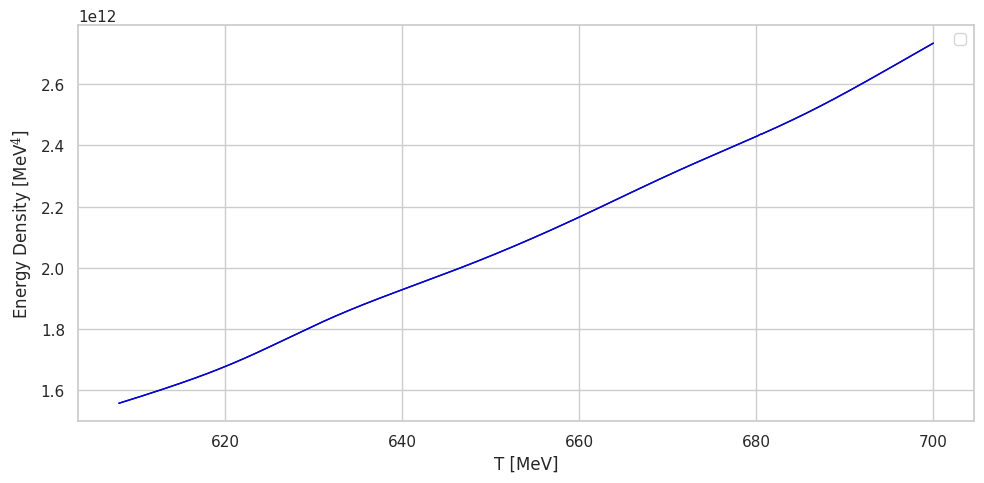

In [68]:
#check up values

#P plot
plt.figure(figsize=(10, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

weighted_vec_test = weightedExtrap(e_hrg_vec_110, e_up_vec)

plt.plot(T_total[50000:], weighted_vec_test[50000:] , '-', linewidth=1, color='black')
plt.plot(T_total[50000:], e_hrg_interp(T_total[50000:]) , '-', linewidth=1, color='blue')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy Density [MeV$^4$]')
plt.legend()
#plt.title('Transition Between HRG and sample values')
plt.grid(True)

plt.tight_layout()
#plt.savefig('./images/P_hrg_150_transition.png')
plt.show()

last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


/tmp/ipykernel_237231/1219723839.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


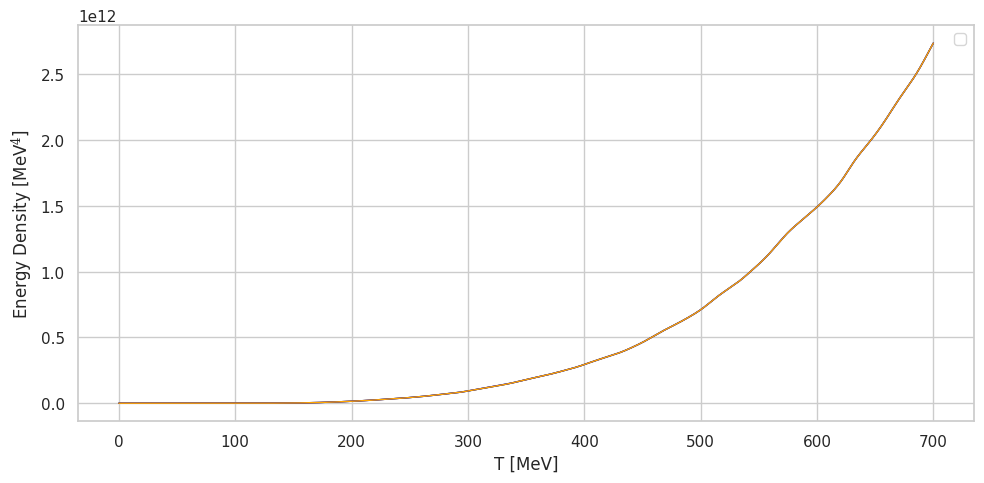

In [69]:
#compare all extrap 

#P plot
plt.figure(figsize=(10, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

weighted_vec_test = weightedExtrap(e_hrg_vec_110, e_up_vec)

plt.plot(T_total, weighted_vec_test , '-', linewidth=1, color='black')
plt.plot(T_total, e_hrg_interp(T_total) , '-', linewidth=1, color='blue')
plt.plot(T_total, e_interp_pwr(T_total) , '-', linewidth=1, color='orange')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy Density [MeV$^4$]')
plt.legend()
#plt.title('Transition Between HRG and sample values')
plt.grid(True)

plt.tight_layout()
#plt.savefig('./images/P_hrg_150_transition.png')
plt.show()

## Saving to file (constrained gp)

In [ ]:
# for constrained GP 

def save_constrained_gp_files(sample_idx, l, sigma):
    cs2_sample_file = generate_sample(l, sigma)
    cs2_interp_file = interp1d(T_stepOne_total, cs2_sample_file)

    s_up_file = entropy_up(s_sw, T_sw, cs2_interp_file, T_pointZeroOne_up)
    P_up_file = pressure_up(P_sw, T_sw, T_pointZeroOne_up, s_up_file)
    P_up_interp_file = interp1d(T_pointZeroOne_up, P_up_file)
    e_up_file = s_up_file(T_pointZeroOne_up)*T_pointZeroOne_up - P_up_interp_file(T_pointZeroOne_up)

    #pwr extrap vectors
    pressure_pwr_file = np.concatenate([P_extrap_pwr(T_pointOne_down, T_pointZeroOne_up, s_up_file, P_up_interp_file), P_up_interp_file(T_pointZeroOne_up)])
    entropy_pwr_file = np.concatenate([s_extrap_pwr(T_pointOne_down, T_pointZeroOne_up, s_up_file, P_up_interp_file), s_up_file(T_pointZeroOne_up)])
    energy_pwr_file = entropy_pwr_file*T_total - pressure_pwr_file
    #discontinuous cs2
    cs2_pwr_file = np.concatenate([cs2_extrap_pwr(T_pointOne_down[0:1100], T_pointZeroOne_up, s_up_file, P_up_interp_file), cs2_interp_file(T_pointZeroOne_up)])
    cs2_pwr_file_interp = interp1d(T_concatenate_110to120, cs2_pwr_file, kind='quadratic')

    #weighted extrap vectors
    pressure_w_file = weightedExtrap(P_hrg_vec_110, P_up_file)
    energy_w_file = weightedExtrap(e_hrg_vec_110, e_up_file)
    entropy_w_file = np.where(T_total != 0, (pressure_w_file + energy_w_file) / T_total, 0.0)
    cs2_120disc_file = np.concatenate([cs2_hrg_120disc, cs2_interp_file(T_pointZeroOne_up)])
    cs2_120disc_interp_file = interp1d(T_total, cs2_120disc_file, kind='quadratic')

    #hrg to 150 vectors
    pressure_hrg_file = np.concatenate([P_hrg_vec_150, P_up_file[3001:]])
    energy_hrg_file = np.concatenate([e_hrg_vec_150, e_up_file[3001:]])
    entropy_hrg_file = np.concatenate([s_hrg_vec_150, s_up_file(T_pointZeroOne_up[3001:])])
    cs2_150disc_file = np.concatenate([cs2_hrg_150disc, cs2_interp_file(T_pointZeroOne_up[3001:])])
    #interpolations (T_pointOne_150 + T_pointZeroOne_up[3001:] is different from T_total)
    cs2_150disc_interp_file = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:]]), cs2_150disc_file, kind='linear')
    pressure_hrg_interp = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:]]), pressure_hrg_file, kind='linear')
    energy_hrg_interp = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:]]), energy_hrg_file, kind='linear')
    entropy_hrg_interp = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:]]), entropy_hrg_file, kind='linear')

    with open(f"./data_files/constrained/l{l}_s{sigma}/eos_pwr_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
        f.write(f"{len(energy_pwr_file)}\n")
        for e, T, p, cs2, s in zip(energy_pwr_file, T_total, pressure_pwr_file, cs2_pwr_file_interp(T_total), entropy_pwr_file):
            f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

    with open(f"./data_files/constrained/l{l}_s{sigma}/eos_w_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
        f.write(f"{len(energy_w_file)}\n")
        for e, T, p, cs2, s in zip(energy_w_file, T_total, pressure_w_file, cs2_120disc_interp_file(T_total), entropy_w_file):
            f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

    with open(f"./data_files/constrained/l{l}_s{sigma}/eos_hrg_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
        f.write(f"{len(energy_hrg_interp(T_total))}\n")
        for e, T, p, cs2, s in zip(energy_hrg_interp(T_total), T_total, pressure_hrg_interp(T_total), cs2_150disc_interp_file(T_total), entropy_hrg_interp(T_total)):
            f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n") 

    with open("./check_files/thermo_check_w_file.txt", "w") as f:

        for i, T in enumerate(T_total):
            s_value = entropy_w_file[i]*(1/hbarc**3)
            p_value = pressure_w_file[i]*(MeV4_to_GeV_fm3)
            e_value = energy_w_file[i]*(MeV4_to_GeV_fm3)
            check = e_value + p_value
            expected = s_value * T*MeV_to_GeV
            diff = abs(check - expected)

            f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")

            if diff > 1e-3:
                print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}")

In [132]:
for i in range(26, 28):
    save_constrained_gp_files(sample_idx=i, l=10, sigma=15) 

last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201
last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


/tmp/ipykernel_237231/955385536.py:23: RuntimeWarning: invalid value encountered in divide
  entropy_w_file = np.where(T_total != 0, (pressure_w_file + energy_w_file) / T_total, 0.0)


last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201
last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


In [ ]:
# changing to evenly spaced energy grid

def save_constrained_evene_files(sample_idx, l, sigma):
    cs2_sample_file = generate_sample(l, sigma)
    cs2_interp_file = interp1d(T_sampling, cs2_sample_file)

    s_up_file = entropy_up(s_sw, T_sw, cs2_interp_file, T_range_up)
    P_up_file = pressure_up(P_sw, T_sw, T_range_up, s_up_file)
    P_up_interp_file = interp1d(T_range_up, P_up_file)
    e_up_file = s_up_file(T_range_up)*T_range_up - P_up_interp_file(T_range_up)

    #hrg to 150 vectors
    pressure_hrg_file = np.concatenate([P_hrg_vec_150, P_up_file[3001:]])
    energy_hrg_file = np.concatenate([e_hrg_vec_150, e_up_file[3001:]])
    entropy_hrg_file = np.concatenate([s_hrg_vec_150, s_up_file(T_range_up[3001:])])
    cs2_to_150_file = np.concatenate([cs2_hrg_to_150, cs2_interp_file(T_range_up[3001:])])

    cs2_interp_150 = interp1d(np.concatenate([T_range_150[:1400],T_range_up[3001:] ]), cs2_to_150_file, kind='cubic')
    pressure_hrg_interp = interp1d(np.concatenate([T_range_150, T_range_up[3001:58001]]), pressure_hrg_file, kind='linear')
    energy_hrg_interp = interp1d(np.concatenate([T_range_150, T_range_up[3001:58001]]), energy_hrg_file, kind='linear')
    entropy_hrg_interp = interp1d(np.concatenate([T_range_150, T_range_up[3001:58001]]), entropy_hrg_file, kind='linear')

    e_grid = np.linspace(0, 472, 59201)

    p_even = interp1d(e_grid, pressure_hrg_interp(T_total)*MeV4_to_GeV_fm3)
    s_even = interp1d(e_grid, entropy_hrg_interp(T_total)*(1/hbarc**3))
    T_even = interp1d(e_grid, T_total)
    cs2_even = interp1d(e_grid, cs2_interp_150(T_total))

    with open(f"./data_files/constrained/eos_hrg_compare_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
        f.write(f"{len(energy_hrg_interp(T_total))}\n")
        for e, T, p, cs2, s in zip(energy_hrg_interp(T_total), T_total, pressure_hrg_interp(T_total), cs2_interp_150(T_total), entropy_hrg_interp(T_total)):
            f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

    with open(f"./data_files/constrained/eos_hrg_even_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
        f.write(f"{len(e_grid)}\n")
        for e, T, p, cs2, s in zip(e_grid, T_even(e_grid), p_even(e_grid), cs2_even(e_grid), s_even(e_grid)):
            f.write(f"{e} {T*MeV_to_GeV} {p} {cs2} {s}\n") 

In [71]:
#save_constrained_evene_files(sample_idx=1, l=10, sigma=15) 

## Unconstrained GP

In [74]:
cs2_cte_mean = np.full((581), 0.5)

def unconstrained_sample(l, sigma):   
    k = []
    mean_unc = [phifromsc2(el) for el in cs2_cte_mean]
    for x1 in T_stepOne_total:
        k_row = []
        for x2 in T_stepOne_total:
            k_row.append(kernel_func(x1, x2, sigma, l)) 
        k.append(k_row)   
    k = np.array(k)
    k[np.diag_indices_from(k)] += 0.001 

    # Cholesky decomposition
    Sigma = cholesky(k)

    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_stepOne_total))
    sample = list(mean_unc + np.dot(Sigma, u))

    # Convert sample using cs2fromphi
    sample = [cs2fromphi(el) for el in sample]

    return sample

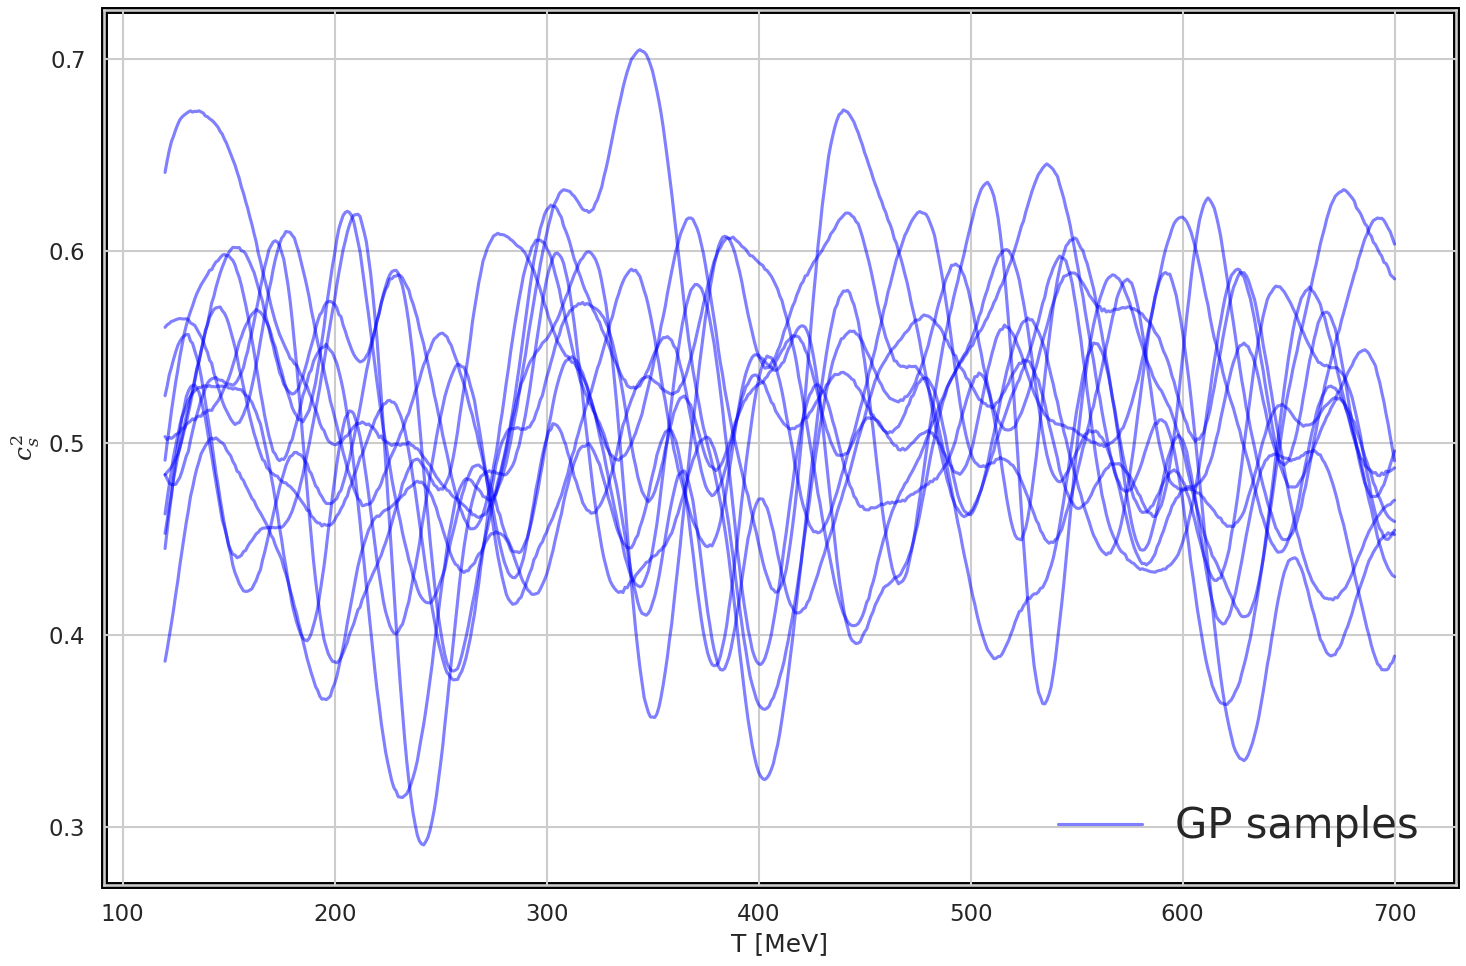

In [75]:
# Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

for i in range(11):
    cs2_sample_uncPlot = unconstrained_sample(15, 30)
    
    ax.plot(
        T_stepOne_total,
        cs2_sample_uncPlot,
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    # ax.plot(
    #     T_down,
    #     y_down,
    #     color='blue',
    #     alpha=0.5,
    #     #label='GP samples' if i == 0 else None
        
    #)

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)

plt.tight_layout()
plt.savefig('./images/cs2_unc.png')
plt.show()

In [109]:
cs2_unc_list = unconstrained_sample(15, 30) #running this changes results below

cs2_interp_unc = interp1d(T_stepOne_total, cs2_unc_list)


In [110]:
#entropy, pressure and energy upwards
s_up_interp_unc = entropy_up(s_sw, T_sw, cs2_interp_unc, T_pointZeroOne_up)

P_up_unc = pressure_up(P_sw, T_sw, T_pointZeroOne_up, s_up_interp_unc)
P_up_interp_unc = interp1d(T_pointZeroOne_up, P_up_unc, kind='linear', fill_value="extrapolate")

e_up_unc = energy_up(s_up_interp_unc, P_up_interp_unc, T_pointZeroOne_up)

### Weighted interpolation

last valid index is 99
n_transition adjusted to 100
len vec_down = 100 len weights = 100 len vec_up = 200 such that the difference should be zero = 0
Final length check: 400 should be 400


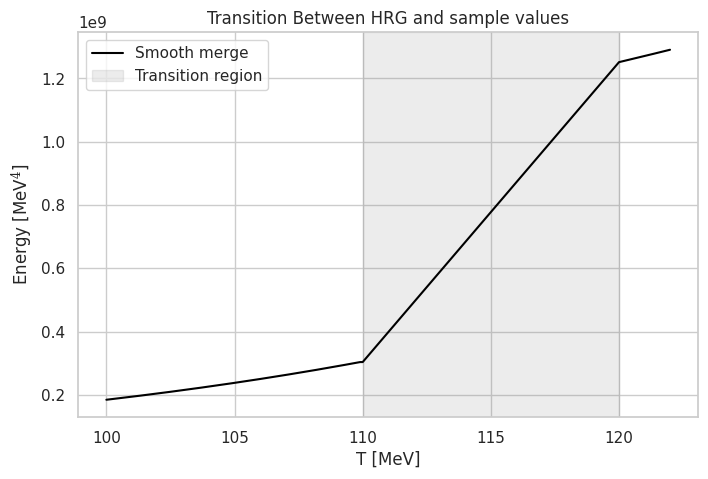

In [111]:
# Energy plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1400], weightedExtrap(e_hrg_vec_110[1000:1100], e_up_unc[0:200]) , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.savefig('./images/hrg_e_transition_unc.png')
plt.show()

719
n_transition adjusted to 481
len vec_down = 719 len weights = 481 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


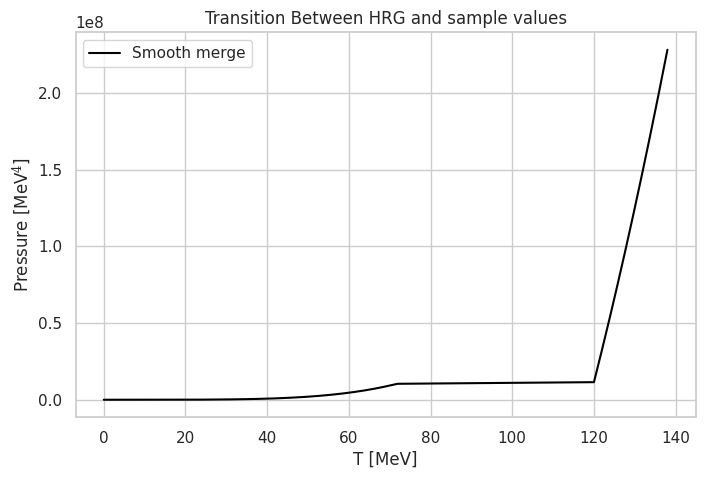

In [118]:
#Pressure plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

p_plot_unc = weightedExtrap(P_hrg_vec_110, P_up_unc)

plt.plot(T_total[:3000], p_plot_unc[:3000] , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(105, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.savefig('./images/hrg_p_transition_unc.png')
plt.show()

last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201
719
n_transition adjusted to 481
len vec_down = 719 len weights = 481 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


/tmp/ipykernel_237231/64720736.py:1: RuntimeWarning: invalid value encountered in divide
  s_plot_unc = ( weightedExtrap(e_hrg_vec_110, e_up_unc) + weightedExtrap(P_hrg_vec_110, P_up_unc))/T_total


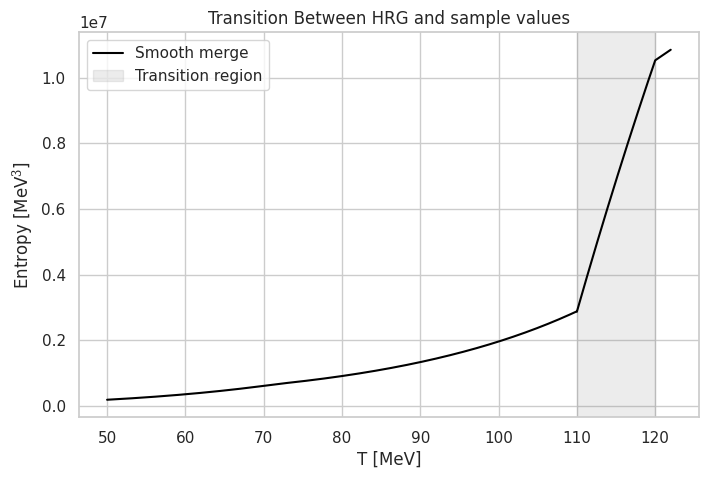

In [115]:
s_plot_unc = ( weightedExtrap(e_hrg_vec_110, e_up_unc) + weightedExtrap(P_hrg_vec_110, P_up_unc))/T_total

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[500:1400], s_plot_unc[500:1400] , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.savefig('./images/hrg_s_transition_unc.png')
plt.show()

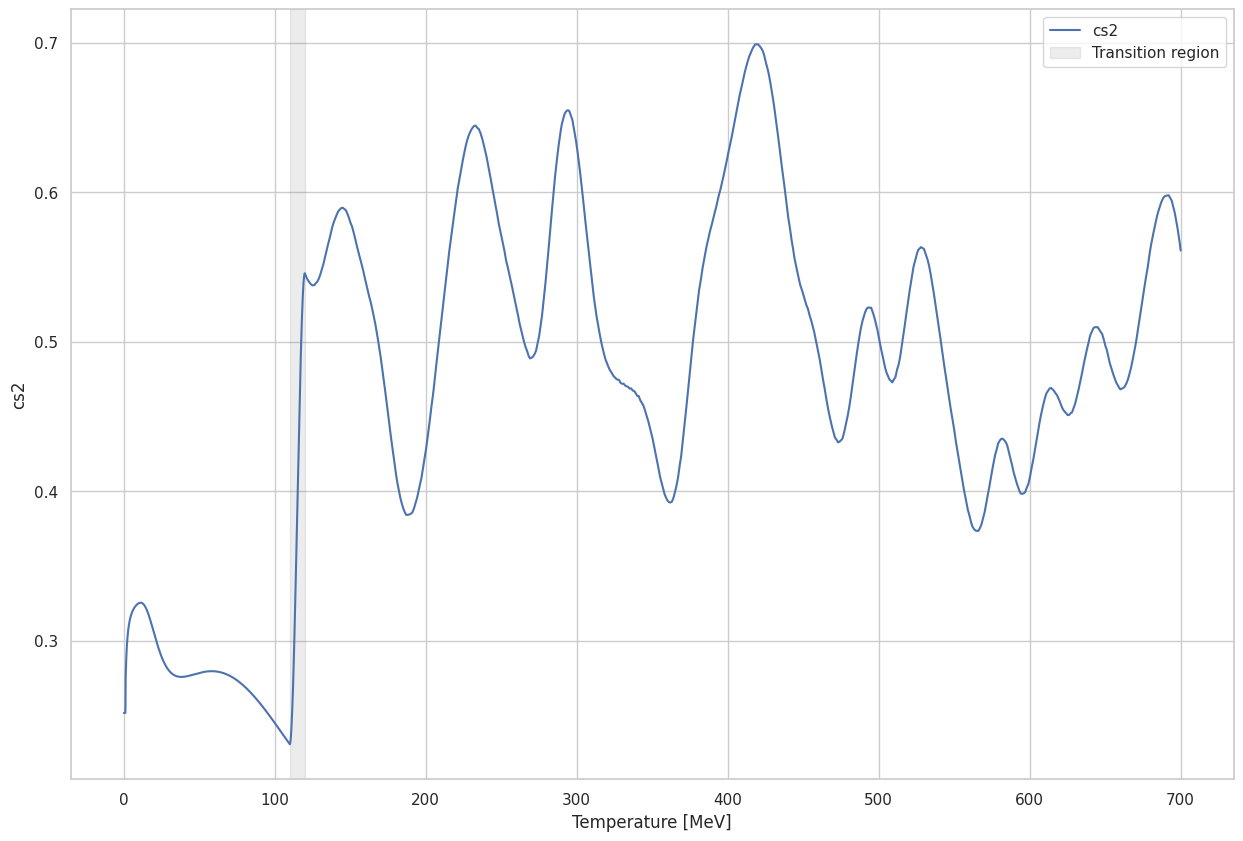

In [119]:
#cs2 

cs2_range_unc = np.concatenate([cs2_hrg_to_interp, cs2_interp_unc(T_pointZeroOne_up)])

cs2_extrap_unc = interp1d(T_concatenate_110to120, cs2_range_unc, kind='cubic')

df = pd.DataFrame({'T': T_total, 'cs2':cs2_extrap_unc(T_total)})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='cs2', label='cs2')

plt.xlabel('Temperature [MeV]')
plt.ylabel('cs2')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.legend()
plt.savefig('./images/cs2_transition_unc.png')
plt.show()

In [120]:
#checking thermodynamic consistency

with open("./check_files/thermo_check_w_unc.txt", "w") as f:
    p_unc = weightedExtrap(P_hrg_vec_110, P_up_unc)
    e_unc = weightedExtrap(e_hrg_vec_110, e_up_unc)
    s_unc = (p_unc + e_unc)/T_total

    for i, T in enumerate(T_total):
        s_value = s_unc[i]
        p_value = p_unc[i]
        e_value = e_unc[i]
        check = e_value + p_value
        expected = s_value * T
        diff = abs(check - expected)

        f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")

        if diff > 1e-3:
            print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}")

719
n_transition adjusted to 481
len vec_down = 719 len weights = 481 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201
last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


/tmp/ipykernel_237231/1013792847.py:6: RuntimeWarning: invalid value encountered in divide
  s_unc = (p_unc + e_unc)/T_total


### Power law extrap

In [90]:
pressure_pwr_unc = np.concatenate([P_extrap_pwr(T_pointOne_down, T_pointZeroOne_up, s_up_interp_unc, P_up_interp_unc), P_up_interp_unc(T_pointZeroOne_up)])
entropy_pwr_unc = np.concatenate([s_extrap_pwr(T_pointOne_down, T_pointZeroOne_up, s_up_interp_unc, P_up_interp_unc), s_up_interp_unc(T_pointZeroOne_up)])
energy_pwr_unc = entropy_pwr_unc*T_total - pressure_pwr_unc

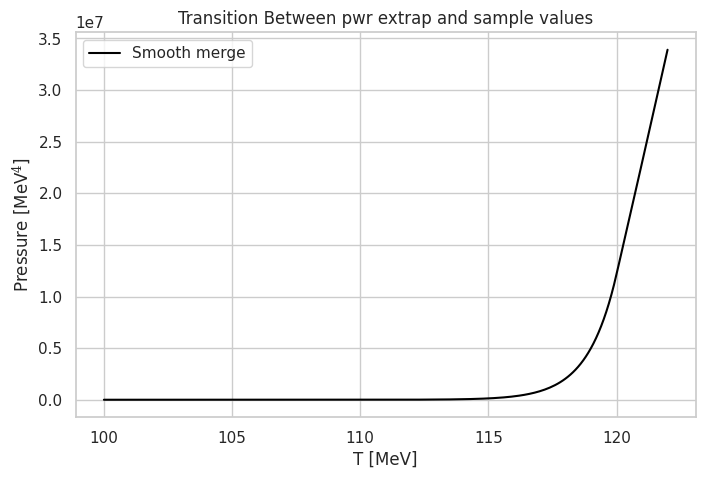

In [121]:
#Pressure plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1400], pressure_pwr_unc[1000:1400] , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(105, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.legend()
plt.title('Transition Between pwr extrap and sample values')
plt.grid(True)
plt.savefig('./images/pwr_p_transition_unc.png')
plt.show()

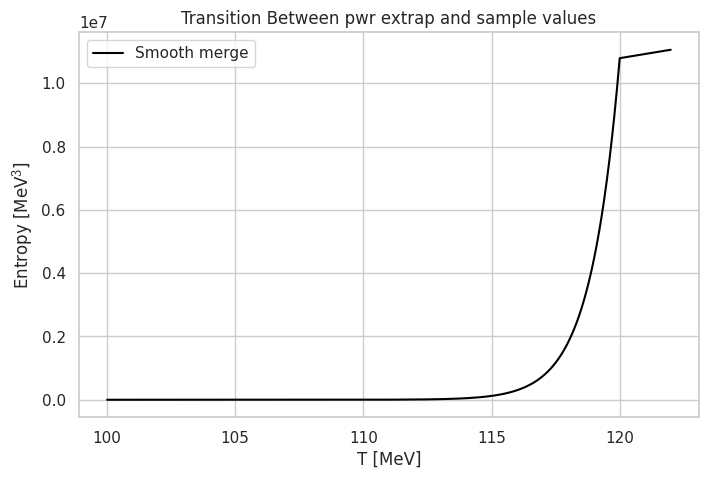

In [122]:
#entropy plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1400], entropy_pwr_unc[1000:1400] , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(105, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.title('Transition Between pwr extrap and sample values')
plt.grid(True)
plt.savefig('./images/pwr_s_transition_unc.png')
plt.show()

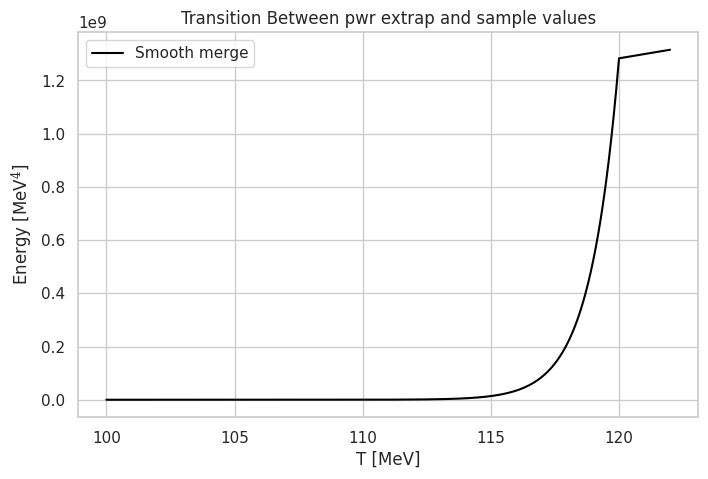

In [123]:
#energy plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1400], energy_pwr_unc[1000:1400] , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(105, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.title('Transition Between pwr extrap and sample values')
plt.grid(True)
plt.savefig('./images/pwr_e_transition_unc.png')
plt.show()

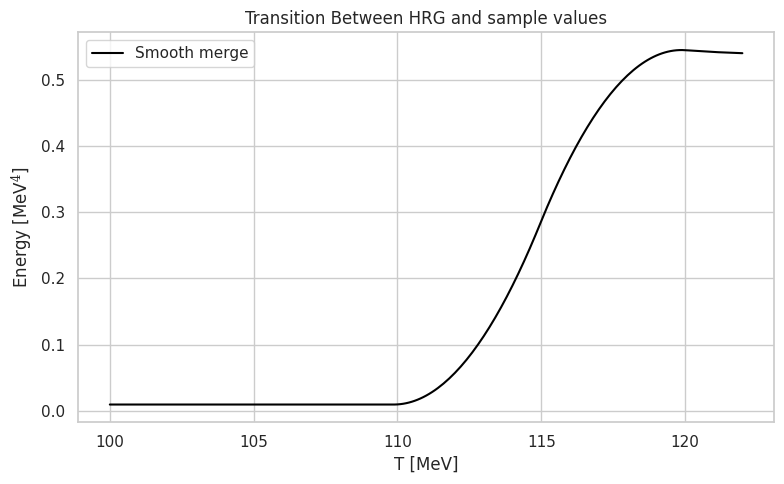

In [124]:
#cs2 

cs2_vec_pwr_unc = np.concatenate([cs2_extrap_pwr(T_pointOne_down[0:1100], T_pointZeroOne_up, s_up_interp_unc, P_up_interp_unc), cs2_interp_unc(T_pointZeroOne_up)])

cs2_pwr_unc = interp1d(T_concatenate_110to120, cs2_vec_pwr_unc, kind='quadratic')


# Plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1400], cs2_pwr_unc(T_total[1000:1400]), '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/pwr_cs2_transition_unc.png')
plt.show()

In [125]:
with open("./check_files/thermo_check_pwr_unc.txt", "w") as f:
    p = pressure_pwr_unc
    e = energy_pwr_unc
    s = (p + e)/T_total

    for i, T in enumerate(T_total):
        s_value = s[i]
        p_value = p[i]
        e_value = e[i]
        check = e_value + p_value
        expected = s_value * T
        diff = abs(check - expected)

        f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")

        if diff > 1e-4:
            print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}")

/tmp/ipykernel_237231/1572279808.py:4: RuntimeWarning: invalid value encountered in divide
  s = (p + e)/T_total


### HRG up to 150 

In [126]:
P_total_150_unc = np.concatenate([P_hrg_vec_150, P_up_unc[3001:]])
e_total_150_unc = np.concatenate([e_hrg_vec_150, e_up_unc[3001:]])
s_total_150_unc = np.concatenate([s_hrg_vec_150, s_up_interp_unc(T_pointZeroOne_up[3001:])])

p_hrg_interp_unc = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:58001]]), P_total_150_unc, kind='linear')
e_hrg_interp_unc = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:58001]]), e_total_150_unc, kind='linear')
s_hrg_interp_unc = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:58001]]), s_total_150_unc, kind='linear')

/tmp/ipykernel_237231/4271538073.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


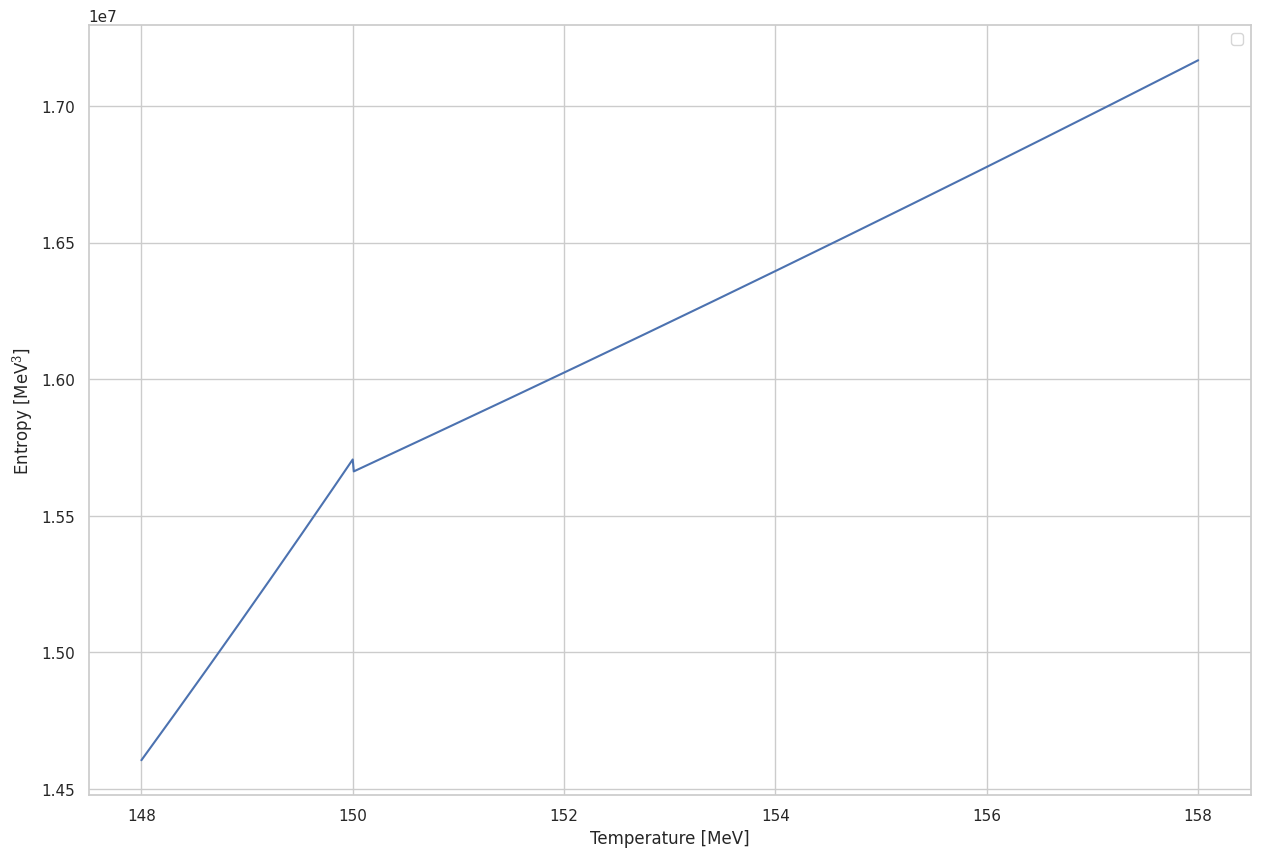

In [127]:
df = pd.DataFrame({'T': T_total[4000:5001], 'pressure': s_hrg_interp_unc(T_total[4000:5001])})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='energy', label='Energy')
sns.lineplot(data=df, x='T', y='pressure')
#sns.lineplot(data=df, x='T', y='sT', label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.savefig('./images/s_unc_hrg_150.png')
plt.show()

/tmp/ipykernel_237231/1900660922.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


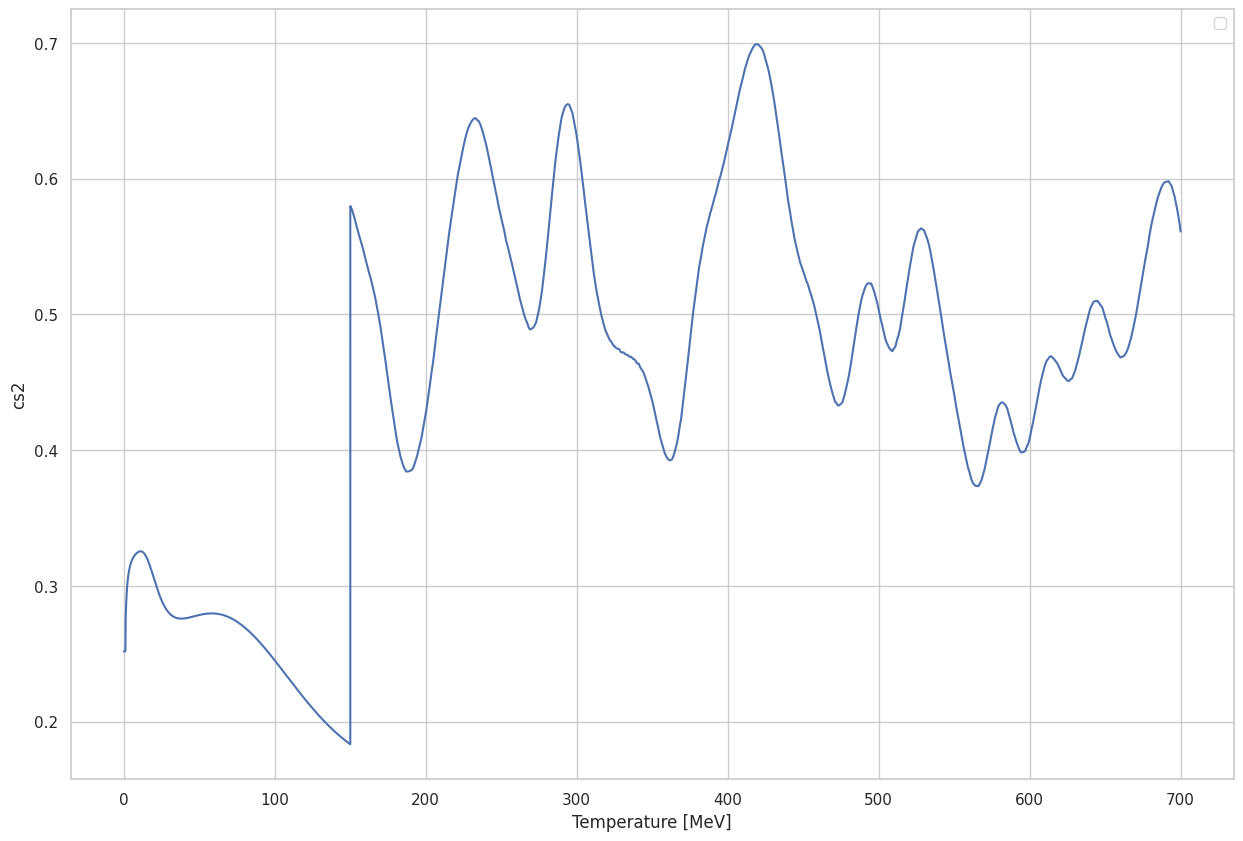

In [135]:
cs2_150disc_unc = np.concatenate([cs2_hrg_150disc, cs2_interp_unc(T_pointZeroOne_up[3001:])])
    #interpolations (T_pointOne_150 + T_pointZeroOne_up[3001:] is different from T_total)
cs2_150_unc_interp = interp1d(np.concatenate([T_pointOne_150,T_pointZeroOne_up[3001:] ]), cs2_150disc_unc, kind='linear')

df = pd.DataFrame({'T': T_total, 'cs2':cs2_150_unc_interp(T_total)})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='energy', label='Energy')
sns.lineplot(data=df, x='T', y='cs2')
#sns.lineplot(data=df, x='T', y='sT', label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('cs2')
plt.legend()
plt.savefig('./images/cs2_unc_hrg_150.png')
plt.show()

## Saving to files (unconstrained gp)

In [136]:
def save_unc_gp_files(sample_idx, l, sigma):
    cs2_unc_file = unconstrained_sample(15, 30) #running this changes results below
    cs2_interp_unc_file = interp1d(T_stepOne_total, cs2_unc_file)

    s_up_unc_file = entropy_up(s_sw, T_sw, cs2_interp_unc_file, T_pointZeroOne_up)
    P_up_unc_file = pressure_up(P_sw, T_sw, T_pointZeroOne_up, s_up_unc_file)
    P_up_unc_interp_file = interp1d(T_pointZeroOne_up, P_up_unc_file, kind='linear', fill_value="extrapolate")   
    e_up_unc_file = s_up_unc_file(T_pointZeroOne_up) * T_pointZeroOne_up - P_up_unc_interp_file(T_pointZeroOne_up)

    #pwr extrap vectors
    pressure_pwr_unc_file = np.concatenate([P_extrap_pwr(T_pointOne_down, T_pointZeroOne_up, s_up_unc_file, P_up_unc_interp_file), P_up_unc_file])
    entropy_pwr_unc_file = np.concatenate([s_extrap_pwr(T_pointOne_down, T_pointZeroOne_up, s_up_unc_file, P_up_unc_interp_file), s_up_unc_file(T_pointZeroOne_up)])
    energy_pwr_unc_file = entropy_pwr_unc_file*T_total - pressure_pwr_unc_file
    cs2_pwr_unc = np.concatenate([cs2_extrap_pwr(T_pointOne_down[0:1100], T_pointZeroOne_up, s_up_unc_file, P_up_unc_interp_file), cs2_interp_unc_file(T_pointZeroOne_up)])
    cs2_pwr_unc_file_interp = interp1d(T_concatenate_110to120, cs2_pwr_unc, kind='quadratic')

    #weighted extrap vectors
    pressure_w_unc_file = weightedExtrap(P_hrg_vec_110, P_up_unc_file)
    energy_w_unc_file = weightedExtrap(e_hrg_vec_110, e_up_unc_file)
    entropy_w_unc_file = np.where(T_total != 0, (pressure_w_unc_file + energy_w_unc_file) / T_total, 0.0)
    cs2_w_unc_file = np.concatenate([cs2_hrg_to_interp, cs2_interp_unc_file(T_pointZeroOne_up)])
    cs2_w_unc_file_interp = interp1d(T_concatenate_110to120, cs2_w_unc_file, kind='quadratic')

    #hrg to 150 vectors
    pressure_hrg_unc_file = np.concatenate([P_hrg_vec_150, P_up_unc_file[3001:]])
    energy_hrg_unc_file = np.concatenate([e_hrg_vec_150, e_up_unc_file[3001:]])
    entropy_hrg_unc_file = np.concatenate([s_hrg_vec_150, s_up_unc_file(T_pointZeroOne_up[3001:])])
    cs2_150disc_unc_file = np.concatenate([cs2_hrg_150disc, cs2_interp_unc_file(T_pointZeroOne_up[3001:])])
    #interpolations (T_pointOne_150 + T_pointZeroOne_up[3001:] is different from T_total)
    cs2_150_unc_file_interp = interp1d(np.concatenate([T_pointOne_150,T_pointZeroOne_up[3001:] ]), cs2_150disc_unc_file, kind='linear')
    pressure_hrg_unc_interp = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:]]), pressure_hrg_unc_file, kind='linear')
    energy_hrg_unc_interp = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:]]), energy_hrg_unc_file, kind='linear')
    entropy_hrg_unc_interp = interp1d(np.concatenate([T_pointOne_150, T_pointZeroOne_up[3001:]]), entropy_hrg_unc_file, kind='linear')

    with open(f"./data_files/unconstrained/l{l}_s{sigma}/eos_pwr_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
        f.write(f"{len(energy_pwr_unc_file)}\n")
        for e, T, p, cs2, s in zip(energy_pwr_unc_file, T_total, pressure_pwr_unc_file, cs2_pwr_unc_file_interp(T_total), entropy_pwr_unc_file):
            f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

    with open(f"./data_files/unconstrained/l{l}_s{sigma}/eos_w_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
        f.write(f"{len(energy_w_unc_file)}\n")
        for e, T, p, cs2, s in zip(energy_w_unc_file, T_total, pressure_w_unc_file, cs2_w_unc_file_interp(T_total), entropy_w_unc_file):
            f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

    with open(f"./data_files/unconstrained/l{l}_s{sigma}/eos_hrg_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
        f.write(f"{len(energy_hrg_unc_interp(T_total))}\n")
        for e, T, p, cs2, s in zip(energy_hrg_unc_interp(T_total), T_total, pressure_hrg_unc_interp(T_total), cs2_150_unc_file_interp(T_total), entropy_hrg_unc_interp(T_total)):
            f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

In [130]:
for i in range(0, 3):
    save_unc_gp_files(sample_idx=i, l=15, sigma=30)

951
n_transition adjusted to 249
len vec_down = 951 len weights = 249 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201
last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


/tmp/ipykernel_237231/282148338.py:20: RuntimeWarning: invalid value encountered in divide
  entropy_w_unc_file = np.where(T_total != 0, (pressure_w_unc_file + energy_w_unc_file) / T_total, 0.0)


781
n_transition adjusted to 419
len vec_down = 781 len weights = 419 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201
last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201
916
n_transition adjusted to 284
len vec_down = 916 len weights = 284 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201
last valid index is 1099
n_transition adjusted to 100
len vec_down = 1100 len weights = 100 len vec_up = 58001 such that the difference should be zero = 0
Final length check: 59201 should be 59201


## Jackknife samples

In [ ]:
T_js = np.linspace(120,260,260-120+1)

j_samples = data.iloc[:, 3:] #selects all lines and all columns after the 3rd
jk_mean = j_samples.mean(axis=1) #mean over each row (axis=1), over the 48 samples for each T
N = j_samples.shape[1]
#print(j_samples.T)

#transpose of j_sample (N_T, N_samples) to (N_samples, N_T), subtracts the mean from each column
X = j_samples.T.sub(jk_mean, axis=1)  

#calculate covariance matrix
var_jk = ((N-1)/N) * ((j_samples.sub(jk_mean, axis=0)) ** 2).sum(axis=1)
cov_matrix = (X.T @ X)*((N-1)/N)

#print(X.T)
#print(cov_matrix)
#print(var_jk)

In [92]:
#correlation matrix

cov_np = cov_matrix.to_numpy()
corr_matrix = np.zeros_like(cov_np)

#print(cov_np[0, 141])

for i in range(0, 140):
    for j in range(0, 140):
        denom = np.sqrt(cov_np[i, i] * cov_np[j, j])
        if denom > 0:
            corr_matrix[i, j] = cov_np[i, j] / denom
        else:
            corr_matrix[i, j] = 0


In [93]:
def is_positive_definite_eig(matrix):
    return np.all(np.linalg.eigvalsh(matrix) >= 1e-10)

print(np.linalg.eigvalsh(cov_matrix))

print(is_positive_definite_eig(cov_matrix)) 


[-1.37953410e-18 -1.00791853e-18 -8.12938652e-19 -4.26212799e-19
 -3.23060037e-19 -3.10271275e-19 -2.43912438e-19 -2.33330365e-19
 -2.13351936e-19 -1.78103056e-19 -1.56530479e-19 -1.41967759e-19
 -1.28934727e-19 -1.22349042e-19 -1.16184186e-19 -1.12074382e-19
 -1.03605560e-19 -1.00509891e-19 -9.86220640e-20 -9.08773574e-20
 -8.69645017e-20 -7.74414775e-20 -7.58653676e-20 -6.83250596e-20
 -6.57249628e-20 -6.47708425e-20 -6.01014723e-20 -5.68009690e-20
 -5.44865352e-20 -5.20517713e-20 -5.03829882e-20 -4.33444677e-20
 -4.20283382e-20 -3.91919948e-20 -3.88044430e-20 -3.50977871e-20
 -3.20519034e-20 -3.16233060e-20 -2.79668829e-20 -2.53664604e-20
 -2.37127779e-20 -2.17925140e-20 -1.77815719e-20 -1.61916935e-20
 -1.48289214e-20 -1.44837973e-20 -1.29571452e-20 -1.02023031e-20
 -8.88129638e-21 -7.38605416e-21 -6.27563017e-21 -5.22978914e-21
 -3.87635315e-21 -2.80733875e-21  8.49453097e-23  1.01091349e-21
  1.09973006e-21  3.13980449e-21  5.63801228e-21  8.26621463e-21
  9.02624088e-21  1.20200

In [95]:
with open("jk_check.txt", "w") as f:
    for i, T in enumerate(T_js):
        diff = (jk_mean - GP_mean_lat_file).iloc[i]
        diff_2 = (lattice_cs2.error - np.sqrt(var_jk)).iloc[i]

        f.write(f"T = {T:.2f} MeV, mean diff = {diff:.2e}, var diff = {diff_2:.2e}\n")


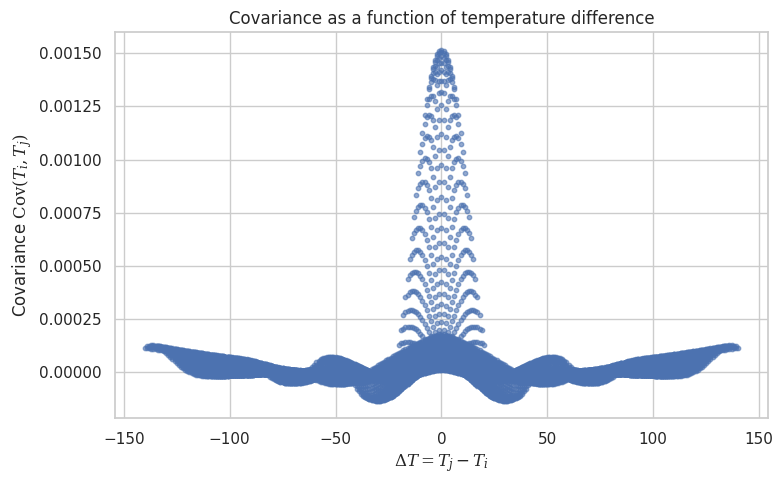

In [96]:
T = data.iloc[:, 0].values
delta_T = T[np.newaxis, :] - T[:, np.newaxis]  # shape: (n_T, n_T)

# Flatten both matrices
delta_T_flat = delta_T.flatten()
cov_flat = cov_matrix.to_numpy().flatten()

# Plot covariance vs. ΔT
plt.figure(figsize=(8, 5))
plt.scatter(delta_T_flat, cov_flat, s=10, alpha=0.6)
plt.xlabel(r'$\Delta T = T_j - T_i$')
plt.ylabel(r'Covariance $\mathrm{Cov}(T_i, T_j)$')
plt.title("Covariance as a function of temperature difference")
plt.grid(True)
plt.tight_layout()

#plt.savefig('cov_matrix.png')
plt.show()

/tmp/ipykernel_5392/1929379322.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', 141)


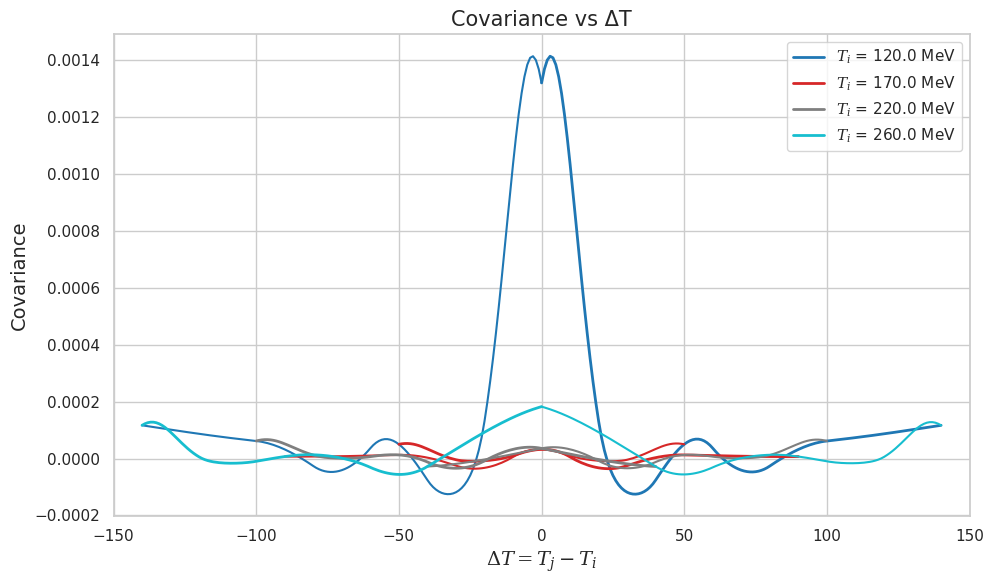

In [97]:
#plot slices

cov = cov_matrix.to_numpy()

plt.figure(figsize=(10, 6))

rows_to_plot = [0, 50, 100, 140]
cmap = cm.get_cmap('tab10', 141)  
colors = [cmap(i) for i in range(141)]
#print(len(colors))

for i in rows_to_plot:
    color = colors[i] 
    delta_T_plus = T - T[i]
    delta_T_minus = T[i] - T
    #delta_T_plot = np.concatenate([delta_T_minus, delta_T_plus])
    #cov_plot = np.concatenate([cov[i, :], cov[i, :]])
    cov_row = cov[i, :]

    plt.plot(delta_T_plus, cov[:, i], color=color, label=rf"$T_i$ = {T[i]:.1f} MeV", linewidth=2)
    plt.plot(delta_T_minus, cov[:, i], color=color)
    #plt.plot(delta_T_plot, cov_plot, label=rf"$T_i$ = {T[i]:.1f} MeV", linewidth=2)

plt.xlabel(r'$\Delta T = T_j - T_i$', fontsize=14)
plt.ylabel('Covariance', fontsize=14)
plt.title('Covariance vs ΔT', fontsize=15)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.xlim(-150, 150)
plt.savefig("./images/covariance_slices.png")
plt.show()

In [98]:
#curve fitting save to file

def gaussian(x, sigma, l):
    return sigma * np.exp(-(x**2) / (2 * l**2))

sigma_fit_vec = []
l_fit_vec = []

with open("gaussian_fit_results.dat", "w") as f:
    f.write("# T    sigma    l\n")
    
    for i in range(len(T)):
        delta_T_plus = T - T[i]
        delta_T_minus = T[i] - T
        delta_T = np.concatenate([delta_T_minus[::-1], delta_T_plus])
        cov_row = np.concatenate([cov[i, ::-1], cov[i, :]])

        try:
            #p0: initial guess for the parameters
            # Here, we use the diagonal element as the initial guess for sigma and a fixed value for l
            popt, _ = curve_fit(gaussian, delta_T, cov_row, p0=[cov[i, i], 10])
            # unpacks the two fitted parameters from popt:
            sigma_fit, l_fit = popt
        except RuntimeError:
            sigma_fit, l_fit = np.nan, np.nan

        sigma_fit_vec.append(sigma_fit)
        l_fit_vec.append(l_fit)

        f.write(f"{T[i]}  {sigma_fit}  {l_fit}\n")


/tmp/ipykernel_5392/2873404945.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', len(rows_to_plot))


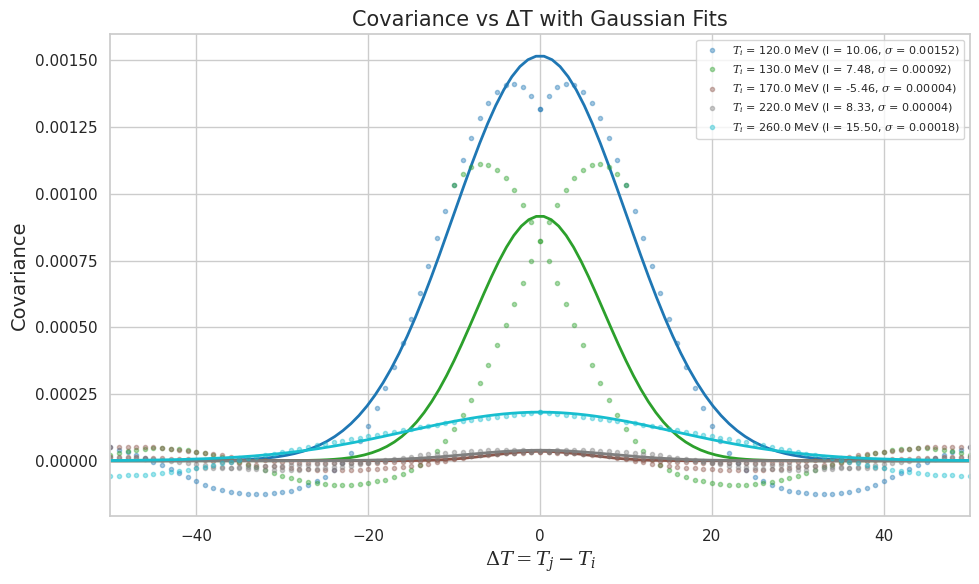

In [99]:
rows_to_plot = [0, 10, 50, 100, 140]
cmap = cm.get_cmap('tab10', len(rows_to_plot))
colors = [cmap(i) for i in range(len(rows_to_plot))]

plt.figure(figsize=(10, 6))

for idx, i in enumerate(rows_to_plot):
    # ΔT for both sides
    delta_T_plus = T - T[i]
    delta_T_minus = T[i] - T
    delta_T = np.concatenate([delta_T_minus[::-1], delta_T_plus])  # symmetric
    cov_row = np.concatenate([cov[i, ::-1], cov[i, :]])  # match order

    # Fit Gaussian
    popt, pcov = curve_fit(gaussian, delta_T, cov_row, p0=[cov[i, i], 10])
    sigma_fit, l_fit = popt

    # Plot data
    plt.plot(delta_T, cov_row, 'o', markersize=3, color=colors[idx], alpha=0.4,
             label=rf"$T_i$ = {T[i]:.1f} MeV (l = {l_fit:.2f}, $\sigma$ = {sigma_fit:.5f})")
    
    # Plot fitted Gaussian
    x_fit = np.linspace(delta_T.min(), delta_T.max(), 300)
    plt.plot(x_fit, gaussian(x_fit, *popt), '-', color=colors[idx], linewidth=2)

plt.xlabel(r'$\Delta T = T_j - T_i$', fontsize=14)
plt.ylabel('Covariance', fontsize=14)
plt.title('Covariance vs ΔT with Gaussian Fits', fontsize=15)
plt.grid(True)
plt.legend(fontsize=8)
plt.tight_layout()
plt.xlim(-50, 50)
plt.savefig("./images/covariance_gaussian_fits.png")
plt.show()

/tmp/ipykernel_5392/1820230671.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')  # continuous colormap


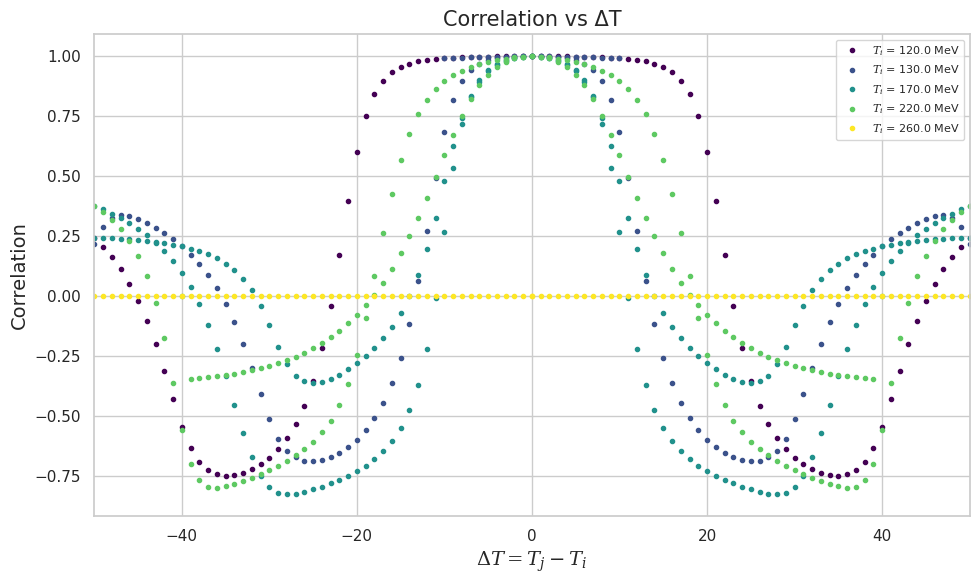

In [100]:
#plot corr matrix


plt.figure(figsize=(10, 6))

rows_to_plot = [0, 10, 50, 100, 140]
""" cmap = cm.get_cmap('viridis', 141)  # or 'coolwarm'
colors = [cmap(i) for i in range(141)] """
#print(len(colors))

cmap = cm.get_cmap('viridis')  # continuous colormap
num_rows = len(rows_to_plot)

for idx, i in enumerate(rows_to_plot):
    color = cmap(idx / (num_rows - 1))

    delta_T_plus = T - T[i]
    delta_T_minus = T[i] - T
    delta_T = np.concatenate([delta_T_minus[::-1], delta_T_plus])  # symmetric
    corr_row = np.concatenate([corr_matrix[i, ::-1], corr_matrix[i, :]])

    plt.plot(delta_T_plus, corr_matrix[i, :], 'o', markersize=3, color=color, label=rf"$T_i$ = {T[i]:.1f} MeV")
    plt.plot(delta_T_minus, corr_matrix[i, :], 'o', markersize=3, color=color)
    #plt.plot(delta_T, corr_row, linewidth=2)


plt.xlabel(r'$\Delta T = T_j - T_i$', fontsize=14)
plt.ylabel('Correlation', fontsize=14)
plt.title('Correlation vs ΔT', fontsize=15)
plt.grid(True)
plt.legend(fontsize=8)
plt.tight_layout()
plt.xlim(-50, 50)
plt.savefig("./images/corr_slices.png")
plt.show()

In [101]:
# k = []
# for x1 in T_js:
#     k_row = []
#     for x2 in T_js:
#         k_row.append(kernel_func(x1, x2, sigma, l)) 
#     k.append(k_row)   
# k = np.array(k)
# k[np.diag_indices_from(k)] += 0.001
# Sigma = cholesky(k)

In [102]:
# T_k = np.array(T_js)
# delta_T_k = T_k[np.newaxis, :] - T_k[:, np.newaxis]

# #transf into 1D array
# delta_T_flat_k = delta_T_k.flatten()
# k_flat = k.flatten()
# sigma_flat = Sigma.flatten()

# # Plot covariance vs. ΔT
# plt.figure(figsize=(8, 5))
# plt.scatter(delta_T_flat_k, k_flat, s=10, alpha=0.6)
# plt.xlabel(r'$\Delta T = T_j - T_i$')
# plt.ylabel(r'Covariance $\mathrm{Cov}(T_i, T_j)$')
# plt.title("Covariance as a function of temperature difference")
# plt.grid(True)
# plt.tight_layout()
# plt.show()

## Kernel with fitted l and sigma

In [103]:
""" def generate_sample_fitted():   
    k = []
    mean = [phifromsc2(el) for el in GP_mean_file]
    for x1, l, sigma in zip(T_sampling[0:141], l_fit_vec, sigma_fit_vec):
        k_row = []
        for x2 in T_sampling[0:141]:
            k_row.append(kernel_func(x1, x2, sigma, l)) 
        k.append(k_row)   
    k = np.array(k)
    k[np.diag_indices_from(k)] += 0.001 

    # Cholesky decomposition
    Sigma = cholesky(k)

    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_sampling[0:141]))
    sample = list(mean + np.dot(Sigma, u))

    # Convert sample using cs2fromphi
    sample = [cs2fromphi(el) for el in sample]

    return sample """

' def generate_sample_fitted():   \n    k = []\n    mean = [phifromsc2(el) for el in GP_mean_file]\n    for x1, l, sigma in zip(T_sampling[0:141], l_fit_vec, sigma_fit_vec):\n        k_row = []\n        for x2 in T_sampling[0:141]:\n            k_row.append(kernel_func(x1, x2, sigma, l)) \n        k.append(k_row)   \n    k = np.array(k)\n    k[np.diag_indices_from(k)] += 0.001 \n\n    # Cholesky decomposition\n    Sigma = cholesky(k)\n\n    # Sample from multivariate normal\n    u = np.random.normal(0, 0.05, len(T_sampling[0:141]))\n    sample = list(mean + np.dot(Sigma, u))\n\n    # Convert sample using cs2fromphi\n    sample = [cs2fromphi(el) for el in sample]\n\n    return sample '

In [104]:
""" # Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

for i in range(11):
    interp_plot = interp1d(T_sampling[0:141], generate_sample_fitted(), kind='cubic', fill_value="extrapolate")
    
    ax.plot(
        T_sampling[0:141],
        interp_plot(T_sampling[0:141]),
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    # ax.plot(
    #     T_down,
    #     y_down,
    #     color='blue',
    #     alpha=0.5,
    #     #label='GP samples' if i == 0 else None
        
    #)

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)

plt.tight_layout()
plt.savefig('./images/cs2_fitted.png')
plt.show() """

' # Seaborn style for better visuals\nsns.set(style="whitegrid", context="talk")\n\n# Assume lat_cs2 is a pandas DataFrame with columns \'T\', \'cs2\', and \'error\'\n\nfig, ax = plt.subplots(figsize=(15, 10))\n\nfor i in range(11):\n    interp_plot = interp1d(T_sampling[0:141], generate_sample_fitted(), kind=\'cubic\', fill_value="extrapolate")\n\n    ax.plot(\n        T_sampling[0:141],\n        interp_plot(T_sampling[0:141]),\n        color=\'blue\',\n        alpha=0.5,\n        label=\'GP samples\' if i == 0 else None\n    )\n\n    # ax.plot(\n    #     T_down,\n    #     y_down,\n    #     color=\'blue\',\n    #     alpha=0.5,\n    #     #label=\'GP samples\' if i == 0 else None\n\n    #)\n\n# Axis labels\nax.set_xlabel("T [MeV]")\nax.set_ylabel(r"$c_s^2$")\n\n# Axis limits\n#ax.set_xlim(120, 700)\n\n# Ticks and frame style\nax.patch.set_edgecolor(\'black\')\nax.patch.set_linewidth(5)\nax.xaxis.set_tick_params(width=5, length=10)\nax.yaxis.set_tick_params(width=5, length=10)\nax.y

## Cs² via jackknife samples

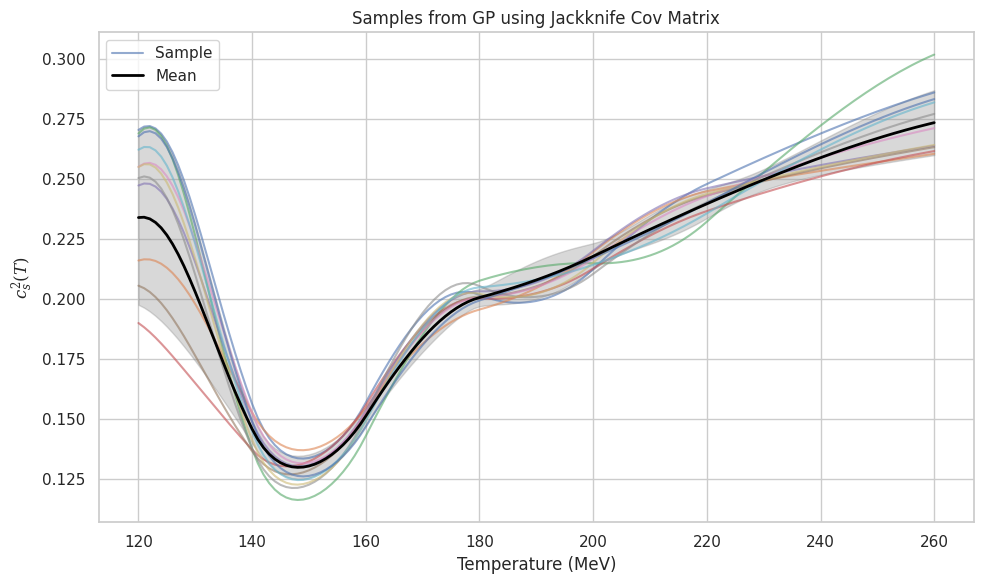

In [105]:
n_samples = 11  # number of functions to draw
jk_cs2 = multivariate_normal(mean=jk_mean, cov=cov_matrix, size=n_samples)

plt.figure(figsize=(10, 6))
for i in range(n_samples):
    plt.plot(T, jk_cs2[i], alpha=0.6, label=f'Sample' if i == 0 else None)

# Plot the mean and uncertainty band
std_diag = np.sqrt(np.diag(cov_matrix))
plt.plot(T, jk_mean, color='black', lw=2, label='Mean')
plt.fill_between(T, jk_mean - std_diag, jk_mean + std_diag, color='gray', alpha=0.3)

plt.xlabel('Temperature (MeV)')
plt.ylabel('$c_s^2(T)$')
plt.title('Samples from GP using Jackknife Cov Matrix')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig('./images/cs2_from_jk.png')
plt.show()